# Самостоятельная реализация оптимизатора

## L-BFGS — регрессия

**Цель работы**

Самостоятельно реализовать квазиньютоновский метод
L-BFGS для обучения полносвязной нейронной сети,
проверить корректность его математических операций
и исследовать сходимость за 120 внешних итераций.

## Постановка задачи

Исходные признаки генерируются независимо
из равномерного распределения:

$$
X\in\mathbb{R}^{240\times2},
\qquad x_{ij}\sim U(-1,1).
$$

Целевая переменная определяется нелинейной зависимостью:

$$
y_i=\tanh\left(1.5x_{i1}
-0.8\sin(\pi x_{i2})\right)+\xi_i,
$$

где

$$
\xi_i\sim\mathcal{N}(0,0.02^2).
$$

Для воспроизводимости генерации данных используется
numpy.random.default_rng(904).
Сначала генерируется матрица признаков, затем шум.

## Параметры эксперимента

| Параметр | Значение |
|---|---|
| Тип задачи | Регрессия |
| Количество наблюдений | 240 |
| Количество исходных признаков | 2 |
| Распределение признаков | $U(-1,1)$ |
| Стандартное отклонение шума | 0.02 |
| Seed генерации данных | 904 |
| Random state разбиения | 1004 |
| Seed инициализации сети | 914 |
| Архитектура сети | 2 → 6 → 1 |
| Активация скрытого слоя | Softplus |
| Активация выходного слоя | Tanh |
| Инициализация весов | Xavier Uniform |
| Инициализация смещений | Нулевая |
| Функция потерь | Половина MSE |
| Оптимизатор | L-BFGS |
| Количество внешних итераций | 120 |
| Размер памяти $m$ | 5 |
| Начальная обратная аппроксимация | $I$ |
| Поиск шага | Армихо |
| Начальный пробный шаг | 1 |
| Коэффициент Армихо $c_1$ | $10^{-4}$ |
| Коэффициент уменьшения шага | 0.5 |
| Максимальное число проб за итерацию | 20 |
| Порог допустимости пары кривизны | $10^{-10}$ |
| Вычислительная точность | float64 |
| Режим обучения | Полная обучающая выборка |
| Вычислительное устройство | CPU |

## Разделение выборки

Данные разделяются на три непересекающиеся части:

| Выборка | Доля | Количество наблюдений | Назначение |
|---|---:|---:|---|
| Train | 70% | 168 | Обучение нейронной сети |
| Validation | 15% | 36 | Выбор лучшей итерации |
| Test | 15% | 36 | Итоговая независимая оценка |

Сначала выделяется тестовая выборка размером 15%
от исходных данных. Затем из оставшейся части
выделяется валидационная выборка в доле 15/85.

Для обоих разбиений используется random_state = 1004.
Поскольку решается задача регрессии, стратификация
не применяется.

## Критерии оценки

**Сходимость и устойчивость**

- Значение функции потерь на обучающей выборке.
- Значение функции потерь на валидационной выборке.
- Норма полного градиента.
- Норма изменения параметров сети.
- Фактическая величина принятого шага.
- Количество принятых и отклонённых шагов.

**Вычислительные затраты**

- Количество вычислений функции потерь.
- Количество вычислений градиента.
- Количество вычислений функции внутри поиска Армихо.
- Количество сохранённых пар кривизны.
- Количество пропущенных пар кривизны.
- Время выполнения.

**Качество регрессии**

- RMSE.
- MAE.

Лучшее состояние нейронной сети выбирается
по минимальному validation loss.
Тестовая выборка используется только для итоговой
оценки качества.

## Условия реализации

Метод L-BFGS, двухцикловая рекурсия, формирование
пар кривизны и поиск шага Армихо реализуются
самостоятельно.

PyTorch используется для представления нейронной сети,
автоматического дифференцирования и операций
линейной алгебры.

Готовые библиотечные оптимизаторы в основном
эксперименте не используются.

Обучение проводится без dropout, batch normalization
и дополнительной регуляризации.

Корректность реализации проверяется отдельно
на аналитическом контрольном примере.

## Математическая структура нейронной сети

Используется полносвязная нейронная сеть с одним
скрытым слоем:

$$
2 \rightarrow 6 \rightarrow 1.
$$

Входной вектор:

$$
x_i=(x_{i1},x_{i2})^T\in\mathbb{R}^2.
$$

**Скрытый слой**

$$
a_i=W_1x_i+b_1,
$$

$$
h_i=\operatorname{Softplus}(a_i),
$$

где

$$
\operatorname{Softplus}(u)=\ln(1+e^u).
$$

**Выходной слой**

$$
z_i=W_2h_i+b_2,
$$

$$
\hat y_i=\tanh(z_i).
$$

Гиперболический тангенс определяется как:

$$
\tanh(u)=\frac{e^u-e^{-u}}{e^u+e^{-u}}.
$$

Выходная активация ограничивает прогнозируемые
значения интервалом $(-1,1)$.

## Параметры нейронной сети

| Параметр | Размерность | Количество элементов |
|---|---|---:|
| $W_1$ | $6\times2$ | 12 |
| $b_1$ | $6$ | 6 |
| $W_2$ | $1\times6$ | 6 |
| $b_2$ | $1$ | 1 |
| Всего | | 25 |

Для применения L-BFGS все обучаемые параметры
объединяются в единый вектор:

$$
\theta=
\begin{pmatrix}
\operatorname{vec}(W_1)\\
b_1\\
\operatorname{vec}(W_2)\\
b_2
\end{pmatrix}
\in\mathbb{R}^{25}.
$$

Начальные матрицы весов формируются методом
Xavier Uniform:

$$
W_{ij}\sim U\left(
-\sqrt{\frac{6}{n_{in}+n_{out}}},
\sqrt{\frac{6}{n_{in}+n_{out}}}
\right).
$$

Для первого слоя:

$$
W_{1,ij}\sim U\left(
-\sqrt{\frac{6}{8}},
\sqrt{\frac{6}{8}}
\right).
$$

Для второго слоя:

$$
W_{2,ij}\sim U\left(
-\sqrt{\frac{6}{7}},
\sqrt{\frac{6}{7}}
\right).
$$

Смещения инициализируются нулями:

$$
b_1=0_6,\qquad b_2=0.
$$

## Целевая функция

В соответствии с условием задания используется
половина средней квадратичной ошибки:

$$
L(\theta)=\frac{1}{2n}
\sum_{i=1}^{n}
(\hat y_i(\theta)-y_i)^2.
$$

Оптимизация проводится по полной обучающей выборке:

$$
L_{\mathrm{train}}(\theta)=
\frac{1}{2n_{\mathrm{train}}}
\sum_{i\in I_{\mathrm{train}}}
(\hat y_i(\theta)-y_i)^2,
$$

где $n_{\mathrm{train}}=168$.

Требуется найти параметры:

$$
\theta_{\mathrm{opt}}=
\arg\min_{\theta\in\mathbb{R}^{25}}
L_{\mathrm{train}}(\theta).
$$

**Градиент целевой функции**

$$
\nabla_\theta L_{\mathrm{train}}(\theta)=
\frac{1}{n_{\mathrm{train}}}
\sum_{i\in I_{\mathrm{train}}}
(\hat y_i-y_i)\nabla_\theta\hat y_i.
$$

Градиент вычисляется с помощью автоматического
дифференцирования PyTorch.

Для оценки сходимости используется евклидова
норма полного градиента:

$$
\|\nabla_\theta L_{\mathrm{train}}(\theta)\|_2=
\sqrt{\sum_{j=1}^{25}
\left(\frac{\partial L_{\mathrm{train}}}
{\partial\theta_j}\right)^2}.
$$

## Метрики качества регрессии

**RMSE — корень из средней квадратичной ошибки**

$$
\operatorname{RMSE}=
\sqrt{\frac{1}{n}
\sum_{i=1}^{n}(\hat y_i-y_i)^2}.
$$

Связь RMSE с используемой функцией потерь:

$$
\operatorname{RMSE}=\sqrt{2L}.
$$

**MAE — средняя абсолютная ошибка**

$$
\operatorname{MAE}=
\frac{1}{n}\sum_{i=1}^{n}|\hat y_i-y_i|.
$$

Меньшие значения RMSE и MAE соответствуют
более высокой точности прогнозирования.

## Выбор итогового состояния сети

После каждой внешней итерации вычисляется
функция потерь на валидационной выборке.

Лучшая итерация определяется по критерию:

$$
t^*=\arg\min_{t\in\{0,\ldots,120\}}
L_{\mathrm{val}}(\theta_t).
$$

Итоговое качество на тестовой выборке оценивается
для параметров $\theta_{t^*}$.

Валидационная и тестовая выборки не участвуют
в вычислении градиентов и обновлении параметров.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from time import perf_counter

# Вычислительная среда
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)

device = torch.device("cpu")

# Параметры генерации данных
n = 240
n_features = 2
seed = 904
sigma = 0.02

split_seed = seed + 100
network_seed = seed + 10

# Архитектура нейронной сети
input_size = 2
hidden_size = 6
output_size = 1

# Параметры L-BFGS
iterations = 120
memory_size = 5
alpha0 = 1.0
c1 = 1e-4
rho = 0.5
max_trials = 20
curvature_tol = 1e-10

# Генерация синтетических данных
rng = np.random.default_rng(seed)

X = rng.uniform(
    -1.0, 1.0,
    size=(n, n_features)
)

noise = rng.normal(
    loc=0.0,
    scale=sigma,
    size=n
)

# Целевая зависимость без шума
y_clean = np.tanh(
    1.5 * X[:, 0]
    - 0.8 * np.sin(np.pi * X[:, 1])
)

# Целевая переменная с шумом
y = y_clean + noise

# Индексы исходных наблюдений
indices = np.arange(n)

# Первое разбиение: 85% / 15%
train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=split_seed,
    shuffle=True
)

# Второе разбиение: 70% / 15% от исходной выборки
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=15 / 85,
    random_state=split_seed,
    shuffle=True
)

# Преобразование выборок в тензоры PyTorch
X_train = torch.tensor(
    X[train_idx],
    dtype=torch.float64,
    device=device
)

y_train = torch.tensor(
    y[train_idx],
    dtype=torch.float64,
    device=device
).reshape(-1, 1)

X_val = torch.tensor(
    X[val_idx],
    dtype=torch.float64,
    device=device
)

y_val = torch.tensor(
    y[val_idx],
    dtype=torch.float64,
    device=device
).reshape(-1, 1)

X_test = torch.tensor(
    X[test_idx],
    dtype=torch.float64,
    device=device
)

y_test = torch.tensor(
    y[test_idx],
    dtype=torch.float64,
    device=device
).reshape(-1, 1)

# Проверка корректности разбиения
assert len(train_idx) == 168
assert len(val_idx) == 36
assert len(test_idx) == 36

assert len(np.intersect1d(train_idx, val_idx)) == 0
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(np.intersect1d(val_idx, test_idx)) == 0

assert np.array_equal(
    np.sort(np.concatenate([
        train_idx, val_idx, test_idx
    ])),
    indices
)

# Проверка точности вычислений
for tensor in [
    X_train, y_train,
    X_val, y_val,
    X_test, y_test
]:
    assert tensor.dtype == torch.float64
    assert torch.isfinite(tensor).all()

# Таблица исходных данных
data = pd.DataFrame({
    "x1": X[:, 0],
    "x2": X[:, 1],
    "y_clean": y_clean,
    "noise": noise,
    "y": y
})

data["split"] = ""

data.loc[train_idx, "split"] = "Train"
data.loc[val_idx, "split"] = "Validation"
data.loc[test_idx, "split"] = "Test"

print("Первые 10 наблюдений обучающей выборки:")

display(
    data.loc[train_idx].head(10).round(6)
)

# Характеристики выборок
split_summary = pd.DataFrame({
    "Выборка": ["Train", "Validation", "Test"],
    "Количество наблюдений": [
        len(train_idx),
        len(val_idx),
        len(test_idx)
    ],
    "Доля": [
        len(train_idx) / n,
        len(val_idx) / n,
        len(test_idx) / n
    ],
    "Размерность X": [
        tuple(X_train.shape),
        tuple(X_val.shape),
        tuple(X_test.shape)
    ],
    "Размерность y": [
        tuple(y_train.shape),
        tuple(y_val.shape),
        tuple(y_test.shape)
    ]
})

display(
    split_summary.style
    .hide(axis="index")
    .format({"Доля": "{:.0%}"})
)

print("Размерность исходной матрицы X:", X.shape)
print("Seed генерации данных:", seed)
print("Seed разбиения:", split_seed)
print("Seed нейронной сети:", network_seed)

print(f"\nСреднее значение шума: {noise.mean():.8f}")
print(f"Стандартное отклонение шума: {noise.std(ddof=1):.8f}")

print("\nВерсия PyTorch:", torch.__version__)
print("Тип данных:", X_train.dtype)
print("Устройство:", device)
print("Количество потоков:", torch.get_num_threads())

print("\nВсе проверки данных и разбиения пройдены.")

Первые 10 наблюдений обучающей выборки:


,x1,x2,y_clean,noise,y,split
50,-0.603757,0.604384,-0.930621,-0.013832,-0.944453,Train
171,0.077232,-0.129832,0.407975,-0.023844,0.384131,Train
56,0.318473,-0.805542,0.733655,0.041554,0.775209,Train
70,0.898421,0.372394,0.544872,-0.009625,0.535248,Train
211,0.262744,0.734500,-0.195870,0.012538,-0.183331,Train
25,-0.173669,0.923000,-0.423658,0.041571,-0.382087,Train
62,0.553119,0.573017,0.050591,-0.016652,0.033939,Train
37,0.439278,0.957831,0.502949,-0.003999,0.498950,Train
112,-0.121949,-0.793027,0.292566,0.012207,0.304772,Train
91,-0.197710,0.304254,-0.739785,0.013126,-0.726659,Train


Выборка,Количество наблюдений,Доля,Размерность X,Размерность y
Train,168,70%,"(168, 2)","(168, 1)"
Validation,36,15%,"(36, 2)","(36, 1)"
Test,36,15%,"(36, 2)","(36, 1)"


Размерность исходной матрицы X: (240, 2)
Seed генерации данных: 904
Seed разбиения: 1004
Seed нейронной сети: 914

Среднее значение шума: 0.00019121
Стандартное отклонение шума: 0.02031547

Версия PyTorch: 2.15.0+cpu
Тип данных: torch.float64
Устройство: cpu
Количество потоков: 1

Все проверки данных и разбиения пройдены.


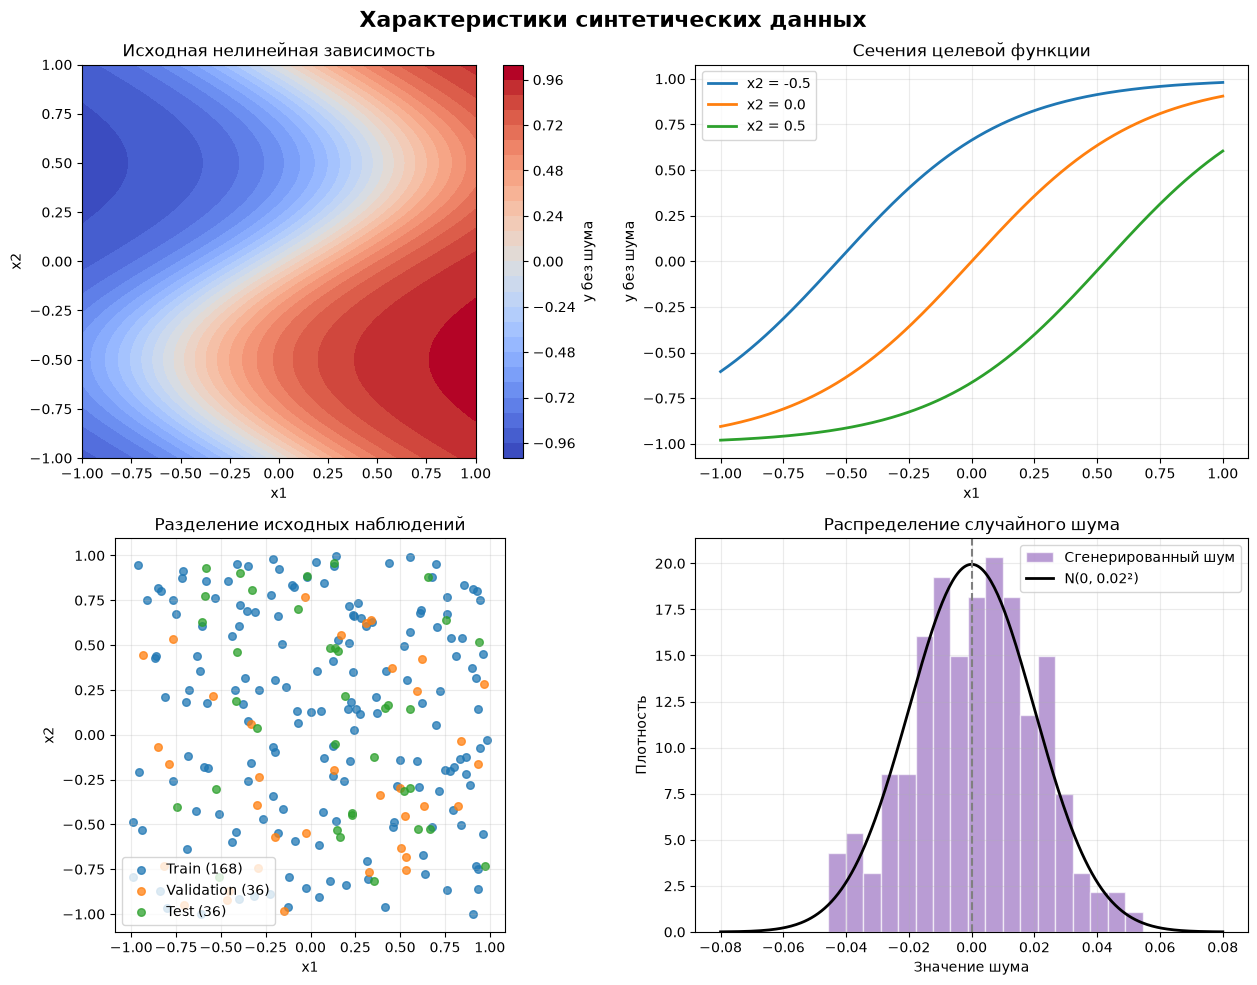

In [4]:
grid = np.linspace(-1, 1, 200)

X1_grid, X2_grid = np.meshgrid(grid, grid)

Y_grid = np.tanh(
    1.5 * X1_grid
    - 0.8 * np.sin(np.pi * X2_grid)
)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# Цветовая карта целевой зависимости
contour = axes[0, 0].contourf(
    X1_grid,
    X2_grid,
    Y_grid,
    levels=30,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

fig.colorbar(contour, ax=axes[0, 0], label="y без шума")

axes[0, 0].set_xlabel("x1")
axes[0, 0].set_ylabel("x2")
axes[0, 0].set_title("Исходная нелинейная зависимость")
axes[0, 0].set_aspect("equal")

# Сечения целевой функции
for x2_fixed in [-0.5, 0.0, 0.5]:

    y_section = np.tanh(
        1.5 * grid
        - 0.8 * np.sin(np.pi * x2_fixed)
    )

    axes[0, 1].plot(
        grid,
        y_section,
        linewidth=2,
        label=f"x2 = {x2_fixed}"
    )

axes[0, 1].set_xlabel("x1")
axes[0, 1].set_ylabel("y без шума")
axes[0, 1].set_title("Сечения целевой функции")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.25)

# Разделение выборок
split_colors = {
    "Train": "#1f77b4",
    "Validation": "#ff7f0e",
    "Test": "#2ca02c"
}

for name, idx in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:

    axes[1, 0].scatter(
        X[idx, 0],
        X[idx, 1],
        color=split_colors[name],
        label=f"{name} ({len(idx)})",
        s=30,
        alpha=0.75
    )

axes[1, 0].set_xlabel("x1")
axes[1, 0].set_ylabel("x2")
axes[1, 0].set_title("Разделение исходных наблюдений")
axes[1, 0].set_aspect("equal")
axes[1, 0].grid(alpha=0.25)
axes[1, 0].legend()

# Распределение шума
axes[1, 1].hist(
    noise[train_idx],
    bins=18,
    density=True,
    color="#9467bd",
    alpha=0.65,
    edgecolor="white",
    label="Сгенерированный шум"
)

noise_grid = np.linspace(-4 * sigma, 4 * sigma, 300)

normal_density = (
    1 / (sigma * np.sqrt(2 * np.pi))
    * np.exp(-noise_grid ** 2 / (2 * sigma ** 2))
)

axes[1, 1].plot(
    noise_grid,
    normal_density,
    color="black",
    linewidth=2,
    label="N(0, 0.02²)"
)

axes[1, 1].axvline(
    0,
    color="gray",
    linestyle="--"
)

axes[1, 1].set_xlabel("Значение шума")
axes[1, 1].set_ylabel("Плотность")
axes[1, 1].set_title("Распределение случайного шума")
axes[1, 1].grid(alpha=0.25)
axes[1, 1].legend()

fig.suptitle(
    "Характеристики синтетических данных",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [5]:
class RegressionNetwork(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):

        h = F.softplus(self.fc1(x))

        return torch.tanh(self.fc2(h))


def initialize_network(seed):

    torch.manual_seed(seed)

    model = RegressionNetwork().to(
        device=device,
        dtype=torch.float64
    )

    with torch.no_grad():

        nn.init.xavier_uniform_(model.fc1.weight)
        nn.init.zeros_(model.fc1.bias)

        nn.init.xavier_uniform_(model.fc2.weight)
        nn.init.zeros_(model.fc2.bias)

    return model


# Инициализация нейронной сети
model = initialize_network(network_seed)


# Преобразование параметров в единый вектор
def get_parameters(model):

    return torch.cat([
        parameter.detach().reshape(-1)
        for parameter in model.parameters()
    ]).clone()


# Восстановление параметров из вектора
def set_parameters(model, theta):

    offset = 0

    with torch.no_grad():

        for parameter in model.parameters():

            size = parameter.numel()

            parameter.copy_(
                theta[offset:offset + size]
                .reshape_as(parameter)
            )

            offset += size

    assert offset == theta.numel()


# Функция потерь — половина MSE
def loss_function(predictions, targets):

    return 0.5 * torch.mean(
        (predictions - targets) ** 2
    )


# Начальный вектор параметров
theta0 = get_parameters(model)

n_parameters = theta0.numel()

# Проверка архитектуры и инициализации
assert n_parameters == 25
assert theta0.dtype == torch.float64

assert torch.all(model.fc1.bias == 0)
assert torch.all(model.fc2.bias == 0)

# Проверка воспроизводимости инициализации
control_model = initialize_network(network_seed)

assert torch.equal(
    theta0,
    get_parameters(control_model)
)

# Проверка обратного преобразования параметров
set_parameters(control_model, theta0 + 0.01)

assert torch.equal(
    get_parameters(control_model),
    theta0 + 0.01
)

set_parameters(control_model, theta0)

assert torch.equal(
    get_parameters(control_model),
    theta0
)

# Проверка границ Xavier Uniform
xavier_bound_1 = np.sqrt(6 / (input_size + hidden_size))
xavier_bound_2 = np.sqrt(6 / (hidden_size + output_size))

assert torch.all(
    torch.abs(model.fc1.weight) <= xavier_bound_1
)

assert torch.all(
    torch.abs(model.fc2.weight) <= xavier_bound_2
)

# Проверка прямого прохода
with torch.no_grad():

    predictions_train = model(X_train)
    predictions_val = model(X_val)

    initial_train_loss = loss_function(
        predictions_train,
        y_train
    ).item()

    initial_val_loss = loss_function(
        predictions_val,
        y_val
    ).item()

assert predictions_train.shape == y_train.shape

assert torch.isfinite(predictions_train).all()

assert torch.all(
    torch.abs(predictions_train) <= 1
)

# Характеристики параметров сети
parameter_records = []

for name, parameter in model.named_parameters():

    values = parameter.detach()

    parameter_records.append({
        "Параметр": name,
        "Размерность": tuple(values.shape),
        "Количество элементов": values.numel(),
        "Минимум": values.min().item(),
        "Максимум": values.max().item(),
        "Среднее": values.mean().item(),
        "Норма": torch.linalg.vector_norm(values).item()
    })

parameter_df = pd.DataFrame(parameter_records)

print("Архитектура нейронной сети:")
print(model)

print("\nКоличество обучаемых параметров:", n_parameters)

print("\nХарактеристики начальных параметров:")

display(
    parameter_df.style.hide(axis="index").format({
        "Минимум": "{:.8f}",
        "Максимум": "{:.8f}",
        "Среднее": "{:.8f}",
        "Норма": "{:.8f}"
    })
)

print("\nГраницы Xavier Uniform:")

print(f"W1: [{-xavier_bound_1:.8f}, {xavier_bound_1:.8f}]")
print(f"W2: [{-xavier_bound_2:.8f}, {xavier_bound_2:.8f}]")

print("\nНачальный вектор параметров:")

print(theta0.numpy())

print(f"\nНачальный train loss: {initial_train_loss:.10f}")
print(f"Начальный validation loss: {initial_val_loss:.10f}")

print("\nВсе проверки архитектуры и инициализации пройдены.")

Архитектура нейронной сети:
RegressionNetwork(
  (fc1): Linear(in_features=2, out_features=6, bias=True)
  (fc2): Linear(in_features=6, out_features=1, bias=True)
)

Количество обучаемых параметров: 25

Характеристики начальных параметров:


Параметр,Размерность,Количество элементов,Минимум,Максимум,Среднее,Норма
fc1.weight,"(6, 2)",12,-0.74189073,0.85613621,0.01003130,1.83461262
fc1.bias,"(6,)",6,0.00000000,0.00000000,0.00000000,0.00000000
fc2.weight,"(1, 6)",6,-0.91271925,-0.19384542,-0.64901467,1.68412619
fc2.bias,"(1,)",1,0.00000000,0.00000000,0.00000000,0.00000000



Границы Xavier Uniform:
W1: [-0.86602540, 0.86602540]
W2: [-0.92582010, 0.92582010]

Начальный вектор параметров:
[-0.45382439  0.36602654 -0.09308898  0.85613621 -0.74189073  0.35612732
 -0.02207758 -0.7179357  -0.37586396  0.51360571 -0.32757487  0.76073599
  0.          0.          0.          0.          0.          0.
 -0.91271925 -0.80387509 -0.65618884 -0.72608089 -0.19384542 -0.60137853
  0.        ]

Начальный train loss: 0.7145280239
Начальный validation loss: 0.8282205202

Все проверки архитектуры и инициализации пройдены.


In [6]:
# Вычисление функции потерь для заданного вектора параметров
def evaluate_loss(model, theta, X_data, y_data):

    set_parameters(model, theta)

    with torch.no_grad():

        predictions = model(X_data)

        value = loss_function(
            predictions,
            y_data
        )

    return value.item()


# Одновременное вычисление потерь и полного градиента
def evaluate_loss_gradient(model, theta, X_data, y_data):

    set_parameters(model, theta)

    predictions = model(X_data)

    value = loss_function(
        predictions,
        y_data
    )

    gradients = torch.autograd.grad(
        value,
        tuple(model.parameters())
    )

    gradient_vector = torch.cat([
        g.detach().reshape(-1)
        for g in gradients
    ])

    return value.item(), gradient_vector


# Вычисление полного градиента в начальной точке
initial_loss, initial_gradient = evaluate_loss_gradient(
    model,
    theta0,
    X_train,
    y_train
)

assert initial_gradient.shape == theta0.shape
assert initial_gradient.dtype == torch.float64
assert torch.isfinite(initial_gradient).all()

assert np.isclose(
    initial_loss,
    initial_train_loss,
    atol=1e-12
)

# Проверка градиента методом центральных разностей
h = 1e-5

numerical_gradient = torch.zeros_like(theta0)

for j in range(n_parameters):

    direction = torch.zeros_like(theta0)
    direction[j] = h

    loss_plus = evaluate_loss(
        model,
        theta0 + direction,
        X_train,
        y_train
    )

    loss_minus = evaluate_loss(
        model,
        theta0 - direction,
        X_train,
        y_train
    )

    numerical_gradient[j] = (
        loss_plus - loss_minus
    ) / (2 * h)

# Абсолютная и относительная погрешности
gradient_difference = (
    initial_gradient - numerical_gradient
)

absolute_error = torch.abs(gradient_difference)

max_absolute_error = absolute_error.max().item()

relative_error = (
    torch.linalg.vector_norm(gradient_difference)
    / torch.linalg.vector_norm(initial_gradient)
).item()

# Таблица сравнения градиентов
gradient_check_df = pd.DataFrame({
    "Параметр": [
        f"theta_{j + 1}"
        for j in range(n_parameters)
    ],

    "Autograd": initial_gradient.numpy(),

    "Центральные разности": numerical_gradient.numpy(),

    "Абсолютная погрешность": absolute_error.numpy()
})

display(
    gradient_check_df.style
    .hide(axis="index")
    .format({
        "Autograd": "{:.10e}",
        "Центральные разности": "{:.10e}",
        "Абсолютная погрешность": "{:.4e}"
    })
)

print(
    f"Начальная норма полного градиента: "
    f"{torch.linalg.vector_norm(initial_gradient).item():.10f}"
)

print(
    f"Максимальная абсолютная погрешность: "
    f"{max_absolute_error:.10e}"
)

print(
    f"Относительная погрешность: "
    f"{relative_error:.10e}"
)

# Проверка совпадения градиентов
assert torch.allclose(
    initial_gradient,
    numerical_gradient,
    atol=1e-8,
    rtol=1e-6
)

# Восстановление начального состояния сети
set_parameters(model, theta0)

assert torch.equal(
    get_parameters(model),
    theta0
)

print("\nПроверка градиента пройдена.")
print("Начальное состояние сети восстановлено.")

Параметр,Autograd,Центральные разности,Абсолютная погрешность
theta_1,6.5946691836e-03,6.5946691774e-03,6.2407e-12
theta_2,-3.5817382448e-03,-3.5817382393e-03,5.4827e-12
theta_3,6.4304604988e-03,6.4304604974e-03,1.3795e-12
theta_4,-2.4733729456e-03,-2.4733729564e-03,1.0889e-11
theta_5,4.0664247160e-03,4.0664247192e-03,3.1288e-12
theta_6,-2.3806020581e-03,-2.3806020655e-03,7.3772e-12
theta_7,7.4882837901e-03,7.4882837930e-03,2.9497e-12
theta_8,-5.4186796577e-03,-5.4186796550e-03,2.7163e-12
theta_9,1.4235540713e-03,1.4235540691e-03,2.2225e-12
theta_10,-7.0307005972e-04,-7.0307005773e-04,1.9883e-12


Начальная норма полного градиента: 0.0663340902
Максимальная абсолютная погрешность: 1.0888966378e-11
Относительная погрешность: 3.8576913354e-10

Проверка градиента пройдена.
Начальное состояние сети восстановлено.


## Метод L-BFGS

L-BFGS (Limited-memory Broyden–Fletcher–Goldfarb–Shanno)
— квазиньютоновский метод оптимизации с ограниченной
памятью.

Метод использует информацию о кривизне целевой
функции, не вычисляя непосредственно матрицу Гессе
и её обратную матрицу.

Обозначим полный градиент обучающей функции потерь:

$$
g_t=\nabla_\theta L_{\mathrm{train}}(\theta_t).
$$

Направление поиска определяется выражением:

$$
d_t=-H_tg_t,
$$

где $H_t$ — приближение обратной матрицы Гессе.

Начальная обратная аппроксимация:

$$
H_0=I_{25}.
$$

## Формирование пар кривизны

После принятия шага вычисляются векторы:

$$
s_t=\theta_{t+1}-\theta_t,
$$

$$
y_t=g_{t+1}-g_t.
$$

Здесь $y_t$ обозначает изменение градиента,
а не целевую переменную регрессионной задачи.

Пара кривизны сохраняется только при выполнении
условия:

$$
s_t^Ty_t>10^{-10}.
$$

Для допустимой пары вычисляется коэффициент:

$$
\rho_t=\frac{1}{s_t^Ty_t}.
$$

В памяти сохраняются не более пяти последних
допустимых пар $(s_t,y_t)$.

При добавлении шестой пары самая старая
пара удаляется.

Если условие кривизны не выполнено, новая пара
не сохраняется, а ранее накопленная история
остаётся неизменной.

## Двухцикловая рекурсия

Для вычисления произведения $H_tg_t$ используется
двухцикловая рекурсия.

Пусть в памяти содержится $k\leq m$ пар,
упорядоченных от самой старой к самой новой.

**Первый цикл**

Инициализация:

$$
q=g_t.
$$

Для сохранённых пар в обратном порядке:

$$
a_i=\rho_i s_i^Tq,
$$

$$
q\leftarrow q-a_i y_i.
$$

**Начальное масштабирование**

Если история пар пуста:

$$
\gamma_t=1.
$$

Если сохранена хотя бы одна допустимая пара,
используется стандартное масштабирование L-BFGS
по последней сохранённой паре:

$$
\gamma_t=
\frac{s_{k-1}^Ty_{k-1}}
{y_{k-1}^Ty_{k-1}}.
$$

Начальный результат второго цикла:

$$
r=\gamma_t q.
$$

**Второй цикл**

Для сохранённых пар в прямом порядке:

$$
b_i=\rho_i y_i^Tr,
$$

$$
r\leftarrow r+s_i(a_i-b_i).
$$

**Направление поиска**

$$
d_t=-r.
$$

При отсутствии сохранённых пар и начальной
аппроксимации $H_0=I$ направление совпадает
с направлением антиградиента:

$$
d_0=-g_0.
$$

Для направления спуска должно выполняться:

$$
g_t^Td_t<0.
$$

Невыполнение этого условия фиксируется
в истории оптимизации.

## Вычислительная сложность

Пусть $p=25$ — количество параметров сети,
$m=5$ — размер памяти L-BFGS.

Вычислительная сложность двухцикловой рекурсии:

$$
O(mp).
$$

Дополнительная память:

$$
O(mp).
$$

При заполненной памяти хранится не более
$2mp$ элементов векторов кривизны:

$$
2\cdot5\cdot25=250.
$$

При использовании float64 объём памяти
векторов кривизны составляет:

$$
250\cdot8=2000\text{ байт}.
$$

Дополнительно сохраняются пять коэффициентов
$\rho_i$, занимающих 40 байт.

Общий объём числовых данных заполненной истории
кривизны:

$$
2000+40=2040\text{ байт}.
$$

Данная оценка не включает параметры сети,
градиенты, временные массивы, историю эксперимента
и служебные структуры Python и PyTorch.

Явное построение матрицы Гессе, её обращение
и решение систем линейных уравнений не требуются.

## Поиск шага по условию Армихо

После определения направления $d_t$ необходимо
выбрать величину шага $\alpha_t$.

Пробное состояние параметров:

$$
\theta_t^{trial}=\theta_t+\alpha d_t.
$$

Шаг принимается при выполнении условия Армихо:

$$
L_{\mathrm{train}}(\theta_t+\alpha d_t)
\leq
L_{\mathrm{train}}(\theta_t)
+c_1\alpha g_t^Td_t.
$$

Параметры поиска согласно варианту:

$$
\alpha_0=1,\qquad c_1=10^{-4},
\qquad \rho=0.5.
$$

Максимальное количество проб на одной внешней
итерации:

$$
K_{\max}=20.
$$

**Последовательность пробных шагов**

$$
\alpha_k=\alpha_0\rho^k,
\qquad k=0,\ldots,19.
$$

На каждой попытке вычисляется функция потерь
в пробной точке.

Если условие Армихо выполнено, шаг принимается:

$$
\theta_{t+1}=\theta_t+\alpha_kd_t.
$$

После принятия шага вычисляется новый полный градиент:

$$
g_{t+1}=\nabla_\theta
L_{\mathrm{train}}(\theta_{t+1}).
$$

Затем формируется новая пара кривизны:

$$
s_t=\theta_{t+1}-\theta_t,
\qquad
y_t=g_{t+1}-g_t.
$$

Если условие Армихо не выполнено,
пробный шаг уменьшается в два раза:

$$
\alpha\leftarrow0.5\alpha.
$$

## Обработка отклонённых шагов

Если за 20 проб условие Армихо не выполнено,
в рамках данной реализации шаг отклоняется:

$$
\theta_{t+1}=\theta_t,
\qquad
g_{t+1}=g_t,
\qquad
\alpha_t=0.
$$

Новая пара кривизны не формируется.

При нечисловом значении пробных потерь попытка
фиксируется как неуспешная, после чего выполняется
уменьшение пробного шага.

Если направление не является направлением спуска,
внешняя итерация фиксируется как отклонённая.

Автоматическая замена направления, изменение
гиперпараметров и повторная инициализация сети
не выполняются.

Количество внешних итераций сохраняется равным 120
независимо от количества принятых шагов.

## Контроль изменения параметров

Фактическая норма обновления:

$$
\|\Delta\theta_t\|_2=
\|\theta_{t+1}-\theta_t\|_2.
$$

Для принятого шага:

$$
\|\Delta\theta_t\|_2=\alpha_t\|d_t\|_2.
$$

Для отклонённого шага:

$$
\|\Delta\theta_t\|_2=0.
$$

При выполнении условия Армихо и наличии направления
спуска обучающая функция потерь уменьшается.

Валидационная функция потерь не участвует
в поиске шага, поэтому её монотонное уменьшение
не гарантируется.

## Учёт вычислительных затрат

Отдельно учитываются:

| Операция | Правило подсчёта |
|---|---|
| Вычисление train loss | Каждый прямой проход по обучающей выборке для расчёта потерь |
| Вычисление полного градиента | Каждый вызов автоматического дифференцирования |
| Поиск Армихо | Каждое вычисление потерь в пробной точке |
| Вычисление validation loss | Каждый диагностический расчёт на валидационной выборке |
| Формирование пары кривизны | После каждого принятого шага |
| Вычисление матрицы Гессе | Не выполняется |
| Решение линейных систем | Не выполняется |

Одновременное вычисление функции потерь и градиента
учитывается как одно вычисление функции и одно
вычисление градиента.

Вычисления функции внутри поиска Армихо входят
в общее количество вычислений train loss.

Диагностические вычисления на валидационной выборке
учитываются отдельно.

## Сохранение истории оптимизации

Для каждой внешней итерации сохраняются:

- вектор параметров нейронной сети;
- train loss;
- validation loss;
- норма полного градиента;
- направление поиска;
- величина принятого шага;
- норма изменения параметров;
- количество проб Армихо;
- статус принятия шага;
- значение $s_t^Ty_t$ при формировании пары;
- состояние памяти L-BFGS;
- накопленные вычислительные затраты;
- время выполнения.

Для каждой пробной попытки поиска Армихо
дополнительно сохраняются:

- номер внешней итерации;
- номер попытки;
- пробный шаг;
- пробный вектор параметров;
- значение обучающей функции потерь;
- правая часть условия Армихо;
- результат проверки условия;
- время и накопленные вычислительные затраты.

Для выполнения общих требований практической работы
также сохраняются validation loss и норма полного
градиента в пробных точках.

Эти дополнительные диагностические вычисления
учитываются отдельно и не влияют на принятие шага
или формирование направления L-BFGS.

In [7]:
def lbfgs_direction(gradient, curvature_history):
    """
    Вычисление направления L-BFGS
    с помощью двухцикловой рекурсии.

    curvature_history содержит тройки (s, y, rho_i),
    упорядоченные от старой пары к новой.
    """

    q = gradient.detach().clone()

    coefficients = []

    # Первый цикл: от новой пары к старой
    for s, y_diff, rho_i in reversed(curvature_history):

        a_i = rho_i * torch.dot(s, q)

        coefficients.append(a_i)

        q = q - a_i * y_diff

    # Масштабирование начальной обратной аппроксимации
    if len(curvature_history) > 0:

        s_last, y_last, _ = curvature_history[-1]

        gamma = (
            torch.dot(s_last, y_last)
            / torch.dot(y_last, y_last)
        ).item()

    else:

        gamma = 1.0

    r = gamma * q

    # Второй цикл: от старой пары к новой
    for (s, y_diff, rho_i), a_i in zip(
        curvature_history,
        reversed(coefficients)
    ):

        b_i = rho_i * torch.dot(y_diff, r)

        r = r + s * (a_i - b_i)

    # Направление оптимизации
    direction = -r

    return direction, gamma


def update_curvature_history(
    curvature_history,
    s,
    y_diff,
    memory_size,
    curvature_tol
):
    """
    Проверка условия кривизны и обновление памяти L-BFGS.
    """

    curvature = torch.dot(s, y_diff).item()

    pair_saved = False
    pair_removed = False

    # Сохранение только допустимых пар
    if np.isfinite(curvature) and curvature > curvature_tol:

        rho_i = 1.0 / curvature

        curvature_history.append((
            s.detach().clone(),
            y_diff.detach().clone(),
            rho_i
        ))

        pair_saved = True

        # Удаление самой старой пары при заполнении памяти
        if len(curvature_history) > memory_size:

            curvature_history.pop(0)

            pair_removed = True

    return curvature, pair_saved, pair_removed


# Проверка направления при пустой памяти
empty_history = []

initial_direction, initial_gamma = lbfgs_direction(
    initial_gradient,
    empty_history
)

# При H0 = I направление равно антиградиенту
assert torch.equal(
    initial_direction,
    -initial_gradient
)

assert initial_gamma == 1.0

# Проверка условия направления спуска
directional_derivative = torch.dot(
    initial_gradient,
    initial_direction
).item()

assert directional_derivative < 0

print("Проверка начального направления L-BFGS:")

print("Количество сохранённых пар:", len(empty_history))

print(f"Коэффициент масштабирования: {initial_gamma:.8f}")

print(
    f"Норма градиента: "
    f"{torch.linalg.vector_norm(initial_gradient).item():.10f}"
)

print(
    f"Норма направления: "
    f"{torch.linalg.vector_norm(initial_direction).item():.10f}"
)

print(
    f"Скалярное произведение g^T d: "
    f"{directional_derivative:.10f}"
)

print("\nНачальное направление совпадает с антиградиентом.")
print("Условие направления спуска выполнено.")
print("Функции L-BFGS определены.")

Проверка начального направления L-BFGS:
Количество сохранённых пар: 0
Коэффициент масштабирования: 1.00000000
Норма градиента: 0.0663340902
Норма направления: 0.0663340902
Скалярное произведение g^T d: -0.0044002115

Начальное направление совпадает с антиградиентом.
Условие направления спуска выполнено.
Функции L-BFGS определены.


In [8]:
# Инициализация счётчиков вычислительных затрат
def initialize_counters():

    return {
        "train_loss_calls": 0,
        "gradient_calls": 0,
        "line_search_calls": 0,
        "validation_loss_calls": 0,
        "diagnostic_train_loss_calls": 0,
        "diagnostic_gradient_calls": 0,
        "curvature_calls": 0,
        "hessian_calls": 0,
        "linear_system_solves": 0
    }


def armijo_line_search(
    theta,
    current_loss,
    gradient,
    direction,
    train_loss_fn,
    train_loss_grad_fn,
    val_loss_fn,
    curvature_history,
    counters,
    iteration,
    start_time,
    alpha0=1.0,
    c1=1e-4,
    rho=0.5,
    max_trials=20
):

    alpha = alpha0

    trial_records = []

    directional_derivative = torch.dot(
        gradient,
        direction
    ).item()

    # Проверка направления спуска
    if (
        not np.isfinite(directional_derivative)
        or directional_derivative >= 0
    ):

        return {
            "theta": theta.clone(),
            "loss": current_loss,
            "alpha": 0.0,
            "accepted": False,
            "status": "Invalid descent direction",
            "trials": trial_records
        }

    # Состояние памяти на момент начала поиска
    memory_snapshot = tuple(
        (s.clone(), y_diff.clone(), rho_i)
        for s, y_diff, rho_i in curvature_history
    )

    # Поиск шага Армихо
    for trial in range(1, max_trials + 1):

        trial_start = perf_counter()

        # Пробные параметры
        theta_trial = theta + alpha * direction

        # Вычисление обучающей функции потерь
        trial_loss = train_loss_fn(theta_trial)

        counters["train_loss_calls"] += 1
        counters["line_search_calls"] += 1

        # Правая часть условия Армихо
        armijo_bound = (
            current_loss
            + c1 * alpha * directional_derivative
        )

        finite_loss = np.isfinite(trial_loss)

        # Проверка условия Армихо
        accepted = bool(
            finite_loss
            and trial_loss <= armijo_bound
        )

        # Дополнительные диагностические вычисления
        # Они не участвуют в выборе пробного шага
        trial_val_loss = val_loss_fn(theta_trial)

        counters["validation_loss_calls"] += 1

        _, trial_gradient = train_loss_grad_fn(
            theta_trial
        )

        counters["diagnostic_train_loss_calls"] += 1
        counters["diagnostic_gradient_calls"] += 1

        trial_gradient_norm = torch.linalg.vector_norm(
            trial_gradient
        ).item()

        # Определение статуса попытки
        if not finite_loss:

            status = "Non-finite loss"

        elif accepted:

            status = "Accepted"

        else:

            status = "Armijo condition failed"

        # Сохранение подробной истории попытки
        trial_records.append({
            "iteration": iteration,
            "trial": trial,
            "alpha": alpha,

            "theta": theta_trial.detach().clone(),
            "gradient": trial_gradient.detach().clone(),
            "direction": direction.detach().clone(),

            "train_loss": trial_loss,
            "validation_loss": trial_val_loss,
            "gradient_norm": trial_gradient_norm,

            "directional_derivative": directional_derivative,
            "armijo_bound": armijo_bound,
            "armijo_margin": armijo_bound - trial_loss,

            "accepted": accepted,
            "status": status,

            "memory_pairs": len(curvature_history),
            "curvature_history": memory_snapshot,

            "trial_time_ms": (
                perf_counter() - trial_start
            ) * 1000,

            "elapsed_time_ms": (
                perf_counter() - start_time
            ) * 1000,

            **counters
        })

        # Принятие шага
        if accepted:

            return {
                "theta": theta_trial.detach().clone(),
                "loss": trial_loss,
                "alpha": alpha,
                "accepted": True,
                "status": "Accepted",
                "trials": trial_records
            }

        # Уменьшение пробного шага
        alpha *= rho

    # Если ни одна из 20 попыток не успешна,
    # параметры остаются неизменными
    return {
        "theta": theta.clone(),
        "loss": current_loss,
        "alpha": 0.0,
        "accepted": False,
        "status": "Maximum trials exceeded",
        "trials": trial_records
    }


print("Функция поиска Армихо определена.")

print("\nПараметры поиска:")
print("Начальный шаг:", alpha0)
print("Коэффициент Армихо:", c1)
print("Коэффициент уменьшения:", rho)
print("Максимальное количество проб:", max_trials)

print("\nСчётчики вычислительных операций:")

display(
    pd.DataFrame(
        initialize_counters().items(),
        columns=["Операция", "Начальное значение"]
    ).style.hide(axis="index")
)

Функция поиска Армихо определена.

Параметры поиска:
Начальный шаг: 1.0
Коэффициент Армихо: 0.0001
Коэффициент уменьшения: 0.5
Максимальное количество проб: 20

Счётчики вычислительных операций:


Операция,Начальное значение
train_loss_calls,0
gradient_calls,0
line_search_calls,0
validation_loss_calls,0
diagnostic_train_loss_calls,0
diagnostic_gradient_calls,0
curvature_calls,0
hessian_calls,0
linear_system_solves,0


In [9]:
def optimize_lbfgs(
    theta0,
    train_loss_fn,
    train_loss_grad_fn,
    val_loss_fn,
    iterations=120,
    memory_size=5,
    alpha0=1.0,
    c1=1e-4,
    rho=0.5,
    max_trials=20,
    curvature_tol=1e-10
):

    start_time = perf_counter()

    theta = theta0.detach().clone()

    curvature_history = []
    history = []
    trial_history = []

    counters = initialize_counters()

    # Начальные потери и градиент
    current_loss, gradient = train_loss_grad_fn(theta)

    counters["train_loss_calls"] += 1
    counters["gradient_calls"] += 1

    initial_validation = val_loss_fn(theta)

    counters["validation_loss_calls"] += 1

    # Начальное состояние: итерация 0
    history.append({
        "iteration": 0,
        "theta": theta.clone(),
        "gradient": gradient.clone(),
        "train_loss": current_loss,
        "validation_loss": initial_validation,
        "gradient_norm": torch.linalg.vector_norm(gradient).item(),
        "direction": torch.zeros_like(theta),
        "directional_derivative": np.nan,
        "direction_norm": 0.0,
        "alpha": 0.0,
        "step_norm": 0.0,
        "gamma": 1.0,
        "trials": 0,
        "accepted": False,
        "status": "Initial state",
        "curvature": np.nan,
        "pair_saved": False,
        "pair_removed": False,
        "memory_pairs": 0,
        "curvature_history": (),
        "iteration_time_ms": 0.0,
        "elapsed_time_ms": (perf_counter() - start_time) * 1000,
        **counters
    })

    # Основной цикл L-BFGS
    for t in range(1, iterations + 1):

        iteration_start = perf_counter()

        # Вычисление направления
        direction, gamma = lbfgs_direction(
            gradient,
            curvature_history
        )

        directional_derivative = torch.dot(
            gradient,
            direction
        ).item()

        # Поиск шага Армихо
        search = armijo_line_search(
            theta=theta,
            current_loss=current_loss,
            gradient=gradient,
            direction=direction,
            train_loss_fn=train_loss_fn,
            train_loss_grad_fn=train_loss_grad_fn,
            val_loss_fn=val_loss_fn,
            curvature_history=curvature_history,
            counters=counters,
            iteration=t,
            start_time=start_time,
            alpha0=alpha0,
            c1=c1,
            rho=rho,
            max_trials=max_trials
        )

        trial_history.extend(search["trials"])

        curvature = np.nan
        pair_saved = False
        pair_removed = False

        step = torch.zeros_like(theta)

        accepted = search["accepted"]
        status = search["status"]

        # Обработка принятого шага
        if accepted:

            theta_new = search["theta"]

            new_loss, gradient_new = train_loss_grad_fn(
                theta_new
            )

            counters["train_loss_calls"] += 1
            counters["gradient_calls"] += 1

            # Проверка численной корректности
            if (
                np.isfinite(new_loss)
                and torch.isfinite(gradient_new).all()
                and torch.isfinite(theta_new).all()
            ):

                # Формирование пары кривизны
                s = theta_new - theta
                y_diff = gradient_new - gradient

                counters["curvature_calls"] += 1

                curvature, pair_saved, pair_removed = (
                    update_curvature_history(
                        curvature_history,
                        s,
                        y_diff,
                        memory_size,
                        curvature_tol
                    )
                )

                # Обновление параметров и градиента
                step = s.clone()

                theta = theta_new.clone()
                gradient = gradient_new.clone()
                current_loss = new_loss

            else:

                accepted = False
                status = "Non-finite parameters or gradient"

        # Валидационная оценка текущего состояния
        validation_loss = val_loss_fn(theta)

        counters["validation_loss_calls"] += 1

        # Сохранение полного состояния памяти
        memory_snapshot = tuple(
            (s.clone(), y_diff.clone(), rho_i)
            for s, y_diff, rho_i in curvature_history
        )

        # Сохранение истории внешней итерации
        history.append({
            "iteration": t,

            "theta": theta.clone(),
            "gradient": gradient.clone(),

            "train_loss": current_loss,
            "validation_loss": validation_loss,

            "gradient_norm": torch.linalg.vector_norm(
                gradient
            ).item(),

            "direction": direction.clone(),

            "directional_derivative": directional_derivative,

            "direction_norm": torch.linalg.vector_norm(
                direction
            ).item(),

            "alpha": search["alpha"] if accepted else 0.0,

            "step_norm": torch.linalg.vector_norm(
                step
            ).item(),

            "gamma": gamma,
            "trials": len(search["trials"]),

            "accepted": accepted,
            "status": status,

            "curvature": curvature,
            "pair_saved": pair_saved,
            "pair_removed": pair_removed,

            "memory_pairs": len(curvature_history),
            "curvature_history": memory_snapshot,

            "iteration_time_ms": (
                perf_counter() - iteration_start
            ) * 1000,

            "elapsed_time_ms": (
                perf_counter() - start_time
            ) * 1000,

            **counters
        })

    return theta, history, trial_history


print("Оптимизатор L-BFGS реализован.")

Оптимизатор L-BFGS реализован.


In [10]:
# Контрольная квадратичная функция
A_control = torch.diag(
    torch.tensor([1.0, 4.0, 8.0], dtype=torch.float64)
)

theta_star_control = torch.tensor(
    [1.0, -2.0, 0.5],
    dtype=torch.float64
)

theta_start_control = torch.tensor(
    [-1.0, 1.0, 2.0],
    dtype=torch.float64
)


def control_loss(theta):

    diff = theta - theta_star_control

    return (0.5 * torch.dot(diff, A_control @ diff)).item()


def control_loss_gradient(theta):

    diff = theta - theta_star_control

    return control_loss(theta), A_control @ diff


# Запуск контрольного эксперимента
theta_control, history_control, trials_control = optimize_lbfgs(
    theta0=theta_start_control,
    train_loss_fn=control_loss,
    train_loss_grad_fn=control_loss_gradient,
    val_loss_fn=control_loss,
    iterations=30,
    memory_size=memory_size,
    alpha0=alpha0,
    c1=c1,
    rho=rho,
    max_trials=max_trials,
    curvature_tol=curvature_tol
)

# Проверка двухцикловой рекурсии
direction_errors = []

I_control = torch.eye(
    theta_start_control.numel(),
    dtype=torch.float64
)

for previous, current in zip(
    history_control[:-1],
    history_control[1:]
):

    pairs = previous["curvature_history"]

    # Начальная обратная аппроксимация
    if pairs:

        s_last, y_last, _ = pairs[-1]

        gamma_reference = (
            torch.dot(s_last, y_last)
            / torch.dot(y_last, y_last)
        )

    else:

        gamma_reference = 1.0

    H = gamma_reference * I_control

    # Явное обратное BFGS-обновление
    for s, y_diff, rho_i in pairs:

        V = I_control - rho_i * torch.outer(s, y_diff)

        H = (
            V @ H @ V.T
            + rho_i * torch.outer(s, s)
        )

    reference_direction = -H @ previous["gradient"]

    direction_error = torch.linalg.vector_norm(
        current["direction"] - reference_direction
    ).item()

    direction_errors.append(direction_error)

    assert torch.allclose(
        current["direction"],
        reference_direction,
        atol=1e-12,
        rtol=1e-10
    )

    # Проверка положительной определённости
    assert torch.all(torch.linalg.eigvalsh(H) > 0)


# Проверка условия Армихо
for trial in trials_control:

    expected_accepted = (
        np.isfinite(trial["train_loss"])
        and trial["train_loss"] <= trial["armijo_bound"]
    )

    assert trial["accepted"] == expected_accepted


# Проверка ограничения размера памяти
assert all(
    record["memory_pairs"] <= memory_size
    for record in history_control
)

# Проверка монотонности обучающих потерь
control_losses = np.array([
    record["train_loss"]
    for record in history_control
])

assert np.all(np.diff(control_losses) <= 1e-12)


# Проверка пропуска недопустимой пары кривизны
test_memory = []

s_test = torch.tensor(
    [1.0, 0.0, 0.0],
    dtype=torch.float64
)

y_test_negative = -s_test

curvature_test, saved_test, removed_test = (
    update_curvature_history(
        test_memory,
        s_test,
        y_test_negative,
        memory_size,
        curvature_tol
    )
)

assert curvature_test < 0
assert not saved_test
assert len(test_memory) == 0


# Проверка удаления старой пары при заполнении памяти
test_memory = []

for k in range(1, memory_size + 2):

    s = k * s_test
    y_diff = A_control @ s

    update_curvature_history(
        test_memory,
        s,
        y_diff,
        memory_size,
        curvature_tol
    )

assert len(test_memory) == memory_size
assert torch.equal(test_memory[0][0], 2 * s_test)


# Итоговые характеристики контрольного эксперимента
control_parameter_error = torch.linalg.vector_norm(
    theta_control - theta_star_control
).item()

assert control_parameter_error < 1e-6

control_summary = pd.DataFrame({
    "Показатель": [
        "Начальные потери",
        "Итоговые потери",
        "Ошибка восстановления параметров",
        "Максимальная погрешность направления",
        "Итоговая норма градиента",
        "Принятые шаги",
        "Вычисления функции внутри поиска Армихо",
        "Максимальное число сохранённых пар"
    ],

    "Значение": [
        control_losses[0],
        control_losses[-1],
        control_parameter_error,
        max(direction_errors),
        history_control[-1]["gradient_norm"],
        sum(r["accepted"] for r in history_control[1:]),
        history_control[-1]["line_search_calls"],
        max(r["memory_pairs"] for r in history_control)
    ]
})

print("Истинное решение:", theta_star_control.numpy())
print("Полученное решение:", theta_control.numpy())

display(
    control_summary.style
    .hide(axis="index")
    .format({"Значение": "{:.10e}"})
)

print("\nВсе контрольные проверки пройдены:")
print("Двухцикловая рекурсия соответствует обратному BFGS.")
print("Положительная определённость сохранена.")
print("Условие Армихо проверяется корректно.")
print("Недопустимые пары кривизны пропускаются.")
print("Ограничение размера памяти соблюдается.")
print("Истинное решение контрольной задачи восстановлено.")

Истинное решение: [ 1.  -2.   0.5]
Полученное решение: [ 1.  -2.   0.5]


Показатель,Значение
Начальные потери,2.9000000000e+01
Итоговые потери,0.0000000000e+00
Ошибка восстановления параметров,0.0000000000e+00
Максимальная погрешность направления,3.1676639674e-16
Итоговая норма градиента,0.0000000000e+00
Принятые шаги,2.6000000000e+01
Вычисления функции внутри поиска Армихо,2.8000000000e+01
Максимальное число сохранённых пар,5.0000000000e+00



Все контрольные проверки пройдены:
Двухцикловая рекурсия соответствует обратному BFGS.
Положительная определённость сохранена.
Условие Армихо проверяется корректно.
Недопустимые пары кривизны пропускаются.
Ограничение размера памяти соблюдается.
Истинное решение контрольной задачи восстановлено.


In [11]:
# Восстановление начального состояния сети
model = initialize_network(network_seed)

assert torch.equal(
    get_parameters(model),
    theta0
)


# Обучающая функция потерь
def train_loss_fn(theta):

    return evaluate_loss(
        model,
        theta,
        X_train,
        y_train
    )


# Обучающая функция потерь и полный градиент
def train_loss_grad_fn(theta):

    return evaluate_loss_gradient(
        model,
        theta,
        X_train,
        y_train
    )


# Валидационная функция потерь
def val_loss_fn(theta):

    return evaluate_loss(
        model,
        theta,
        X_val,
        y_val
    )


# Основной эксперимент
theta_final, history, trial_history = optimize_lbfgs(
    theta0=theta0,
    train_loss_fn=train_loss_fn,
    train_loss_grad_fn=train_loss_grad_fn,
    val_loss_fn=val_loss_fn,
    iterations=iterations,
    memory_size=memory_size,
    alpha0=alpha0,
    c1=c1,
    rho=rho,
    max_trials=max_trials,
    curvature_tol=curvature_tol
)

# Установка итоговых параметров
set_parameters(model, theta_final)

# Формирование таблицы внешних итераций
history_df = pd.DataFrame([
    {
        key: value
        for key, value in record.items()
        if key not in [
            "theta",
            "gradient",
            "direction",
            "curvature_history"
        ]
    }
    for record in history
])

# Формирование таблицы пробных попыток Армихо
trials_df = pd.DataFrame([
    {
        key: value
        for key, value in record.items()
        if key not in [
            "theta",
            "gradient",
            "direction",
            "curvature_history"
        ]
    }
    for record in trial_history
])

# История всех параметров сети
theta_history = torch.stack([
    record["theta"]
    for record in history
]).numpy()

# Основные проверки
assert len(history) == iterations + 1

assert theta_history.shape == (121, 25)

assert history_df["memory_pairs"].max() <= memory_size

assert history_df["trials"].max() <= max_trials

assert torch.equal(
    history[0]["theta"],
    theta0
)

assert torch.equal(
    history[-1]["theta"],
    theta_final
)

# Проверка счётчиков вычислительных затрат
last_record = history[-1]

assert last_record["line_search_calls"] == len(trial_history)

assert last_record["diagnostic_gradient_calls"] == len(trial_history)

assert last_record["diagnostic_train_loss_calls"] == len(trial_history)

assert last_record["train_loss_calls"] == (
    last_record["gradient_calls"]
    + last_record["line_search_calls"]
)

assert last_record["validation_loss_calls"] == (
    1 + iterations + len(trial_history)
)

# Количество принятых и отклонённых шагов
accepted_steps = int(
    history_df.iloc[1:]["accepted"].sum()
)

rejected_steps = iterations - accepted_steps

# Выбор лучшей итерации по validation loss
best_iteration = int(
    history_df["validation_loss"].idxmin()
)

theta_best = history[best_iteration]["theta"].clone()

# Итоговая таблица
training_summary = pd.DataFrame({
    "Показатель": [
        "Количество внешних итераций",
        "Принятые шаги",
        "Отклонённые шаги",
        "Начальный train loss",
        "Итоговый train loss",
        "Начальный validation loss",
        "Итоговый validation loss",
        "Минимальный validation loss",
        "Лучшая итерация",
        "Начальная норма градиента",
        "Итоговая норма градиента",
        "Максимальное количество пар",
        "Количество проб Армихо",
        "Время выполнения, мс"
    ],

    "Значение": [
        iterations,
        accepted_steps,
        rejected_steps,
        history[0]["train_loss"],
        history[-1]["train_loss"],
        history[0]["validation_loss"],
        history[-1]["validation_loss"],
        history[best_iteration]["validation_loss"],
        best_iteration,
        history[0]["gradient_norm"],
        history[-1]["gradient_norm"],
        history_df["memory_pairs"].max(),
        len(trial_history),
        history[-1]["elapsed_time_ms"]
    ]
})

print("Основной эксперимент завершён.")

display(
    training_summary.style
    .hide(axis="index")
    .format({"Значение": "{:.10g}"})
)

# Просмотр истории оптимизации
history_columns = [
    "iteration",
    "train_loss",
    "validation_loss",
    "gradient_norm",
    "alpha",
    "step_norm",
    "trials",
    "memory_pairs",
    "accepted"
]

print("\nПервые пять состояний:")

display(
    history_df[history_columns].head(5)
    .style.hide(axis="index")
    .format({
        "train_loss": "{:.10f}",
        "validation_loss": "{:.10f}",
        "gradient_norm": "{:.6e}",
        "alpha": "{:.6f}",
        "step_norm": "{:.6e}"
    })
)

print("\nПоследние пять состояний:")

display(
    history_df[history_columns].tail(5)
    .style.hide(axis="index")
    .format({
        "train_loss": "{:.10f}",
        "validation_loss": "{:.10f}",
        "gradient_norm": "{:.6e}",
        "alpha": "{:.6f}",
        "step_norm": "{:.6e}"
    })
)

print("\nРазмерность истории параметров:", theta_history.shape)
print("Количество записей внешних итераций:", len(history_df))
print("Количество записей пробных попыток:", len(trials_df))

print("\nСтатусы внешних итераций:")

display(
    history_df.iloc[1:]["status"].value_counts()
)

print("\nТестовая выборка пока не использовалась.")

Основной эксперимент завершён.


Показатель,Значение
Количество внешних итераций,120
Принятые шаги,120
Отклонённые шаги,0
Начальный train loss,0.7145280239
Итоговый train loss,0.01173908098
Начальный validation loss,0.8282205202
Итоговый validation loss,0.01461492283
Минимальный validation loss,0.01461492283
Лучшая итерация,120
Начальная норма градиента,0.06633409018



Первые пять состояний:


iteration,train_loss,validation_loss,gradient_norm,alpha,step_norm,trials,memory_pairs,accepted
0,0.7145280239,0.8282205202,6.633409e-02,0.000000,0.000000e+00,0,0,False
1,0.7095696984,0.8219949848,8.377857e-02,1.000000,6.633409e-02,1,0,True
2,0.7014334625,0.8117892363,1.116479e-01,1.000000,8.377857e-02,1,0,True
3,0.6863452378,0.7928959986,1.612802e-01,1.000000,1.116479e-01,1,0,True
4,0.6525606276,0.7507579494,2.645569e-01,1.000000,1.612802e-01,1,0,True



Последние пять состояний:


iteration,train_loss,validation_loss,gradient_norm,alpha,step_norm,trials,memory_pairs,accepted
116,0.0127565026,0.0163896262,7.877006e-02,1.000000,3.357753e-01,1,5,True
117,0.0124979614,0.0160387007,4.363707e-02,1.000000,1.394831e-01,1,5,True
118,0.0119871485,0.0153970559,6.654978e-02,1.000000,3.819620e-01,1,5,True
119,0.0118662365,0.0152147320,5.143863e-02,1.000000,7.610171e-02,1,5,True
120,0.0117390810,0.0146149228,4.602345e-02,1.000000,2.587751e-01,1,5,True



Размерность истории параметров: (121, 25)
Количество записей внешних итераций: 121
Количество записей пробных попыток: 155

Статусы внешних итераций:


status
Accepted    120
Name: count, dtype: int64


Тестовая выборка пока не использовалась.


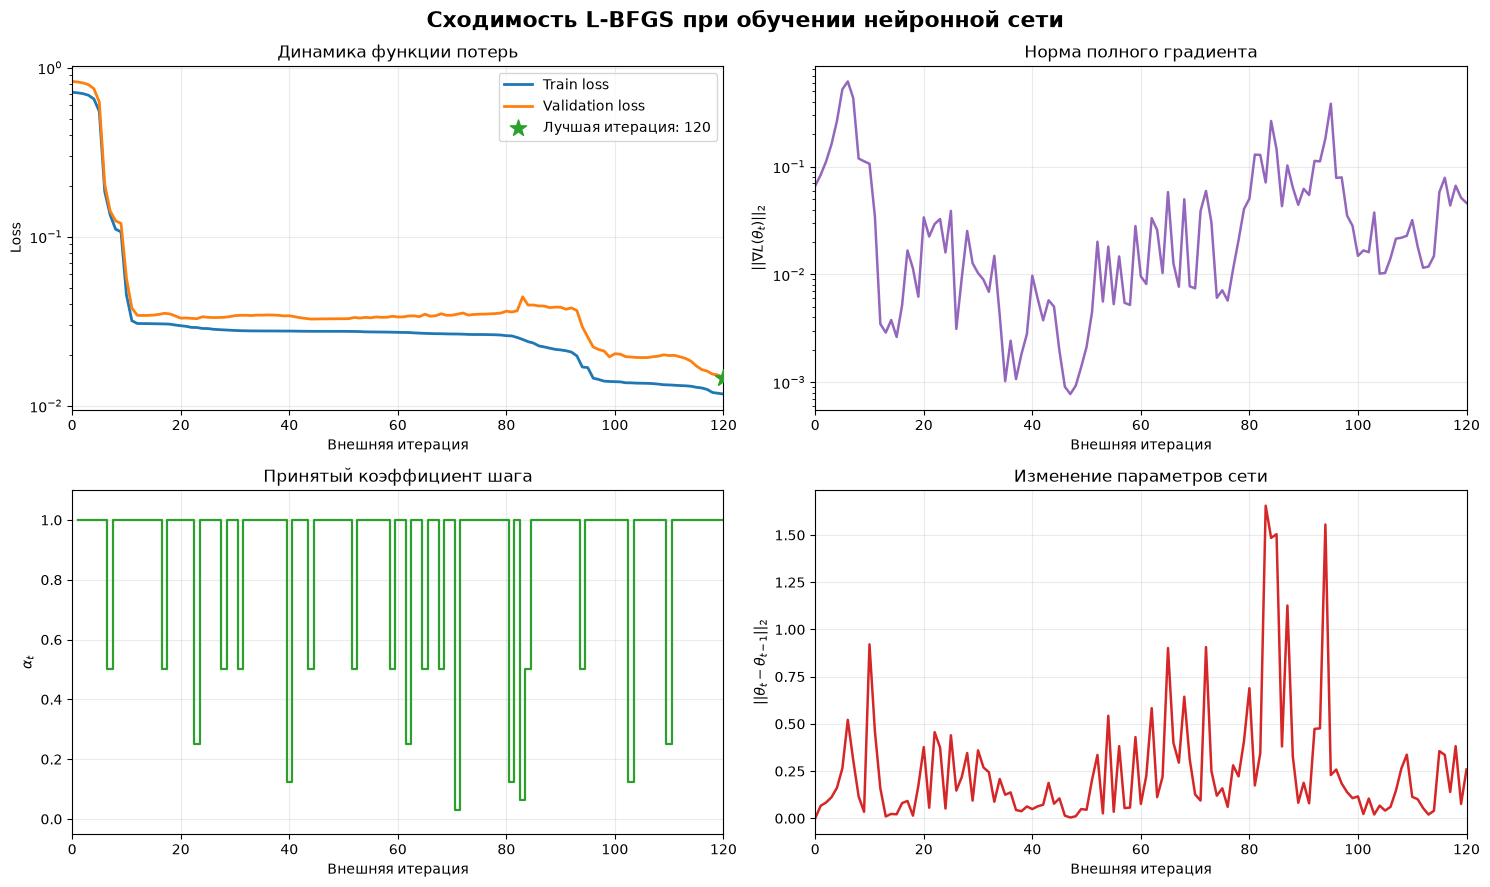

Уменьшение train loss: 98.3571%
Уменьшение validation loss: 98.2354%

Количество итераций с увеличением потерь:
Train: 0
Validation: 52

Минимальная норма градиента: 7.7673857714e-04
Итерация минимальной нормы градиента: 47

Максимальная норма изменения параметров: 1.6551892075


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Динамика функции потерь
axes[0, 0].plot(
    history_df["iteration"],
    history_df["train_loss"],
    color="#1f77b4",
    linewidth=2,
    label="Train loss"
)

axes[0, 0].plot(
    history_df["iteration"],
    history_df["validation_loss"],
    color="#ff7f0e",
    linewidth=2,
    label="Validation loss"
)

axes[0, 0].scatter(
    best_iteration,
    history_df.loc[best_iteration, "validation_loss"],
    color="#2ca02c",
    marker="*",
    s=150,
    zorder=5,
    label=f"Лучшая итерация: {best_iteration}"
)

axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Динамика функции потерь")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()

# Норма полного градиента
axes[0, 1].plot(
    history_df["iteration"],
    history_df["gradient_norm"],
    color="#9467bd",
    linewidth=1.8
)

axes[0, 1].set_title("Норма полного градиента")
axes[0, 1].set_ylabel(r"$||\nabla L(\theta_t)||_2$")
axes[0, 1].set_yscale("log")

# Фактическая величина шага Армихо
axes[1, 0].step(
    history_df["iteration"].iloc[1:],
    history_df["alpha"].iloc[1:],
    where="mid",
    color="#2ca02c",
    linewidth=1.6
)

axes[1, 0].set_title("Принятый коэффициент шага")
axes[1, 0].set_ylabel(r"$\alpha_t$")
axes[1, 0].set_ylim(-0.05, 1.1)

# Норма изменения параметров
axes[1, 1].plot(
    history_df["iteration"],
    history_df["step_norm"],
    color="#d62728",
    linewidth=1.8
)

axes[1, 1].set_title("Изменение параметров сети")
axes[1, 1].set_ylabel(r"$||\theta_t-\theta_{t-1}||_2$")

for ax in axes.flat:

    ax.set_xlabel("Внешняя итерация")
    ax.grid(alpha=0.25)
    ax.set_xlim(0, iterations)

fig.suptitle(
    "Сходимость L-BFGS при обучении нейронной сети",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Количественная оценка уменьшения потерь
train_reduction = (
    1 - history[-1]["train_loss"]
    / history[0]["train_loss"]
)

val_reduction = (
    1 - history[-1]["validation_loss"]
    / history[0]["validation_loss"]
)

# Проверка монотонности обучающих потерь
train_differences = np.diff(
    history_df["train_loss"].to_numpy()
)

train_increases = np.sum(
    train_differences > 1e-12
)

val_differences = np.diff(
    history_df["validation_loss"].to_numpy()
)

val_increases = np.sum(
    val_differences > 1e-12
)

print(f"Уменьшение train loss: {train_reduction:.4%}")
print(f"Уменьшение validation loss: {val_reduction:.4%}")

print("\nКоличество итераций с увеличением потерь:")
print("Train:", train_increases)
print("Validation:", val_increases)

print(f"\nМинимальная норма градиента: "
      f"{history_df['gradient_norm'].min():.10e}")

print(f"Итерация минимальной нормы градиента: "
      f"{history_df['gradient_norm'].idxmin()}")

print(f"\nМаксимальная норма изменения параметров: "
      f"{history_df['step_norm'].max():.10f}")

Показатель,Значение
Всего проб Армихо,155
Успешные пробы,120
Неуспешные пробы,35
"Шаги, принятые с первой попытки",101
Итерации с уменьшением шага,19
Среднее количество проб за итерацию,1.2916667
Максимальное количество проб за итерацию,6
Минимальный принятый коэффициент шага,0.03125
Сформированные пары кривизны,120
Допустимые сохранённые пары,114



Распределение принятых коэффициентов шага:


Коэффициент шага,Количество итераций
1.00000000,101
0.50000000,11
0.25000000,3
0.12500000,3
0.06250000,1
0.03125000,1


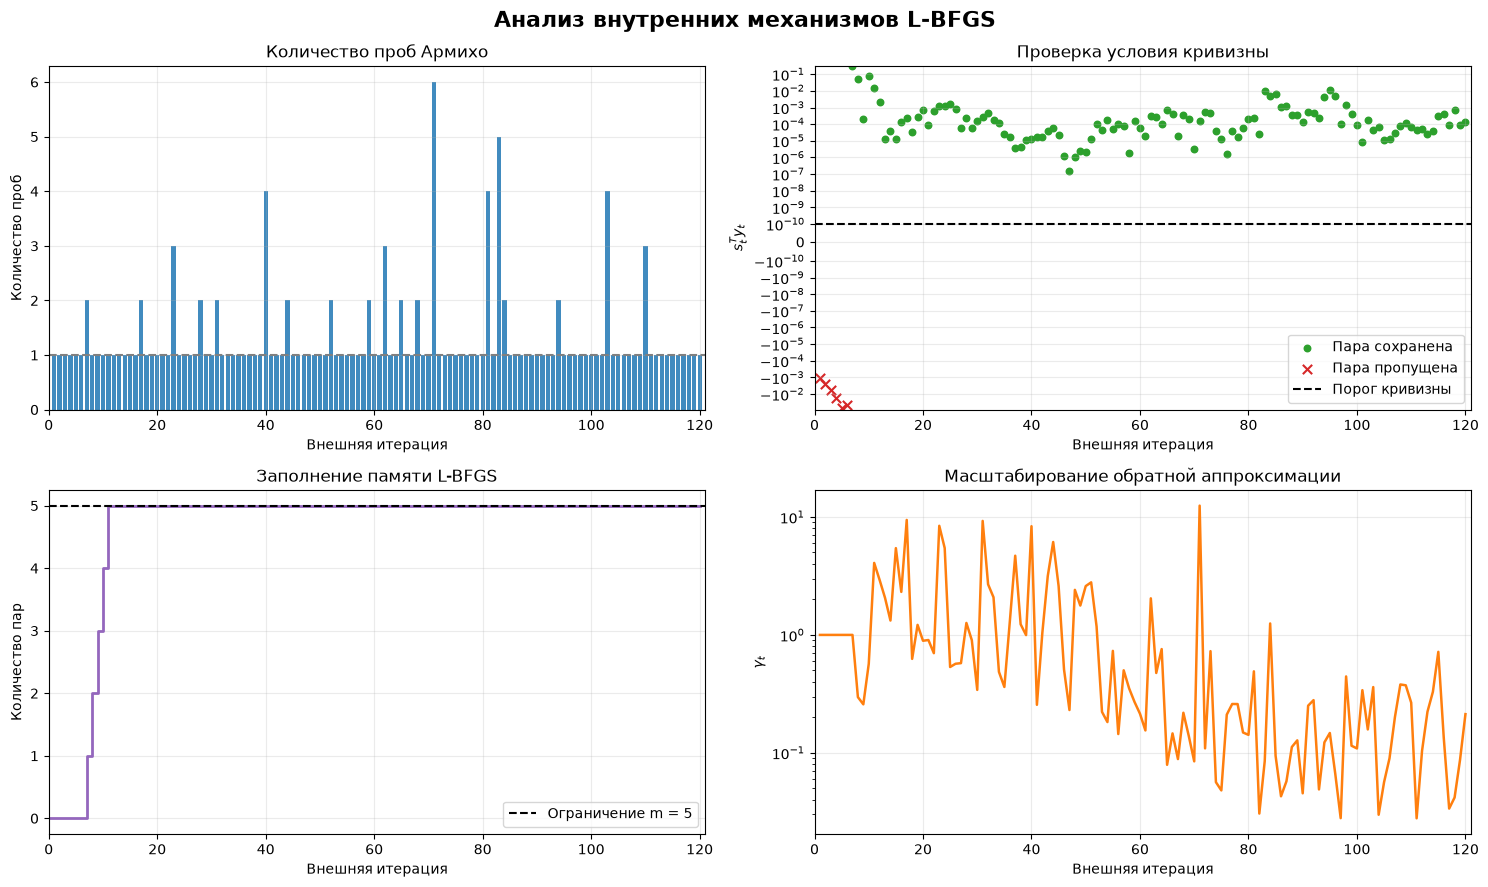

Все проверки механизмов L-BFGS пройдены.


In [13]:
iteration_df = history_df.iloc[1:].copy()

# Проверка принятых шагов
accepted_trials = trials_df[trials_df["accepted"]]

rejected_trials = trials_df[~trials_df["accepted"]]

assert (
    accepted_trials["train_loss"]
    <= accepted_trials["armijo_bound"]
).all()

assert (
    iteration_df.loc[
        iteration_df["accepted"],
        "directional_derivative"
    ] < 0
).all()

# Анализ сохранения пар кривизны
saved_pairs = int(iteration_df["pair_saved"].sum())

removed_pairs = int(iteration_df["pair_removed"].sum())

formed_pairs = int(
    iteration_df["curvature"].notna().sum()
)

skipped_pairs = formed_pairs - saved_pairs

assert (
    iteration_df.loc[
        iteration_df["pair_saved"],
        "curvature"
    ] > curvature_tol
).all()

assert saved_pairs - removed_pairs == (
    history_df["memory_pairs"].iloc[-1]
)

# Количество шагов, принятых с первой попытки
first_trial_steps = int(
    (
        iteration_df["accepted"]
        & (iteration_df["trials"] == 1)
    ).sum()
)

backtracking_steps = int(
    (iteration_df["trials"] > 1).sum()
)

# Сводная таблица
mechanism_summary = pd.DataFrame({
    "Показатель": [
        "Всего проб Армихо",
        "Успешные пробы",
        "Неуспешные пробы",
        "Шаги, принятые с первой попытки",
        "Итерации с уменьшением шага",
        "Среднее количество проб за итерацию",
        "Максимальное количество проб за итерацию",
        "Минимальный принятый коэффициент шага",
        "Сформированные пары кривизны",
        "Допустимые сохранённые пары",
        "Пропущенные пары",
        "Удалённые из заполненной памяти пары",
        "Итоговое количество пар в памяти"
    ],

    "Значение": [
        len(trials_df),
        len(accepted_trials),
        len(rejected_trials),
        first_trial_steps,
        backtracking_steps,
        iteration_df["trials"].mean(),
        iteration_df["trials"].max(),

        iteration_df.loc[
            iteration_df["accepted"], "alpha"
        ].min(),

        formed_pairs,
        saved_pairs,
        skipped_pairs,
        removed_pairs,
        history_df["memory_pairs"].iloc[-1]
    ]
})

display(
    mechanism_summary.style
    .hide(axis="index")
    .format({"Значение": "{:.8g}"})
)

# Распределение принятых коэффициентов шага
alpha_distribution = (
    iteration_df.loc[
        iteration_df["accepted"], "alpha"
    ]
    .value_counts()
    .sort_index(ascending=False)
    .rename_axis("Коэффициент шага")
    .reset_index(name="Количество итераций")
)

print("\nРаспределение принятых коэффициентов шага:")

display(
    alpha_distribution.style
    .hide(axis="index")
    .format({"Коэффициент шага": "{:.8f}"})
)

# Визуализация работы механизмов
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Количество проб Армихо
axes[0, 0].bar(
    iteration_df["iteration"],
    iteration_df["trials"],
    color="#1f77b4",
    alpha=0.85
)

axes[0, 0].axhline(
    1,
    color="gray",
    linestyle="--"
)

axes[0, 0].set_title("Количество проб Армихо")
axes[0, 0].set_ylabel("Количество проб")

# Значения условия кривизны
saved = iteration_df[iteration_df["pair_saved"]]

skipped = iteration_df[
    iteration_df["curvature"].notna()
    & ~iteration_df["pair_saved"]
]

axes[0, 1].scatter(
    saved["iteration"],
    saved["curvature"],
    color="#2ca02c",
    s=22,
    label="Пара сохранена"
)

axes[0, 1].scatter(
    skipped["iteration"],
    skipped["curvature"],
    color="#d62728",
    marker="x",
    s=45,
    label="Пара пропущена"
)

axes[0, 1].axhline(
    curvature_tol,
    color="black",
    linestyle="--",
    label="Порог кривизны"
)

axes[0, 1].set_yscale(
    "symlog",
    linthresh=1e-10
)

axes[0, 1].set_title("Проверка условия кривизны")
axes[0, 1].set_ylabel(r"$s_t^T y_t$")
axes[0, 1].legend()

# Заполнение памяти L-BFGS
axes[1, 0].step(
    history_df["iteration"],
    history_df["memory_pairs"],
    where="post",
    color="#9467bd",
    linewidth=2
)

axes[1, 0].axhline(
    memory_size,
    color="black",
    linestyle="--",
    label=f"Ограничение m = {memory_size}"
)

axes[1, 0].set_title("Заполнение памяти L-BFGS")
axes[1, 0].set_ylabel("Количество пар")
axes[1, 0].set_yticks(range(memory_size + 1))
axes[1, 0].legend()

# Масштабирование обратной аппроксимации
axes[1, 1].plot(
    iteration_df["iteration"],
    iteration_df["gamma"],
    color="#ff7f0e",
    linewidth=1.8
)

axes[1, 1].set_yscale("log")

axes[1, 1].set_title(
    "Масштабирование обратной аппроксимации"
)

axes[1, 1].set_ylabel(r"$\gamma_t$")

for ax in axes.flat:

    ax.set_xlabel("Внешняя итерация")
    ax.set_xlim(0, iterations + 1)
    ax.grid(alpha=0.25)

fig.suptitle(
    "Анализ внутренних механизмов L-BFGS",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Все проверки механизмов L-BFGS пройдены.")

Вычислительные затраты:


Операция,Оптимизация,Диагностика,Всего
Вычисления train loss,276,155,431
Вычисления validation loss,0,276,276
Вычисления полного градиента,121,155,276
Индивидуальные градиенты,20328,26040,46368
Формирование и проверка пар кривизны,120,0,120
Вычисления матрицы Гессе,0,0,0
Решения линейных систем,0,0,0



Вычисления функции внутри поиска Армихо: 155
Общее количество вычислений функции потерь: 707
Общее количество вычислений полного градиента: 276

Временные характеристики:


Показатель,Значение
"Полное время эксперимента, мс",138.817900
"Среднее время внешней итерации, мс",1.149308
"Медианное время внешней итерации, мс",0.946200
"Стандартное отклонение времени, мс",0.498755
"Минимальное время итерации, мс",0.822000
"Максимальное время итерации, мс",4.606700
"Суммарное время проб Армихо, мс",68.631301



Теоретическая оценка памяти:


Показатель,Значение
Количество параметров сети,25
"Размер одного элемента float64, байт",8
"Размер вектора параметров, байт",200
"Размер одной пары с коэффициентом rho, байт",408
Максимальное количество сохранённых пар,5
"Размер заполненной памяти L-BFGS, байт",2040


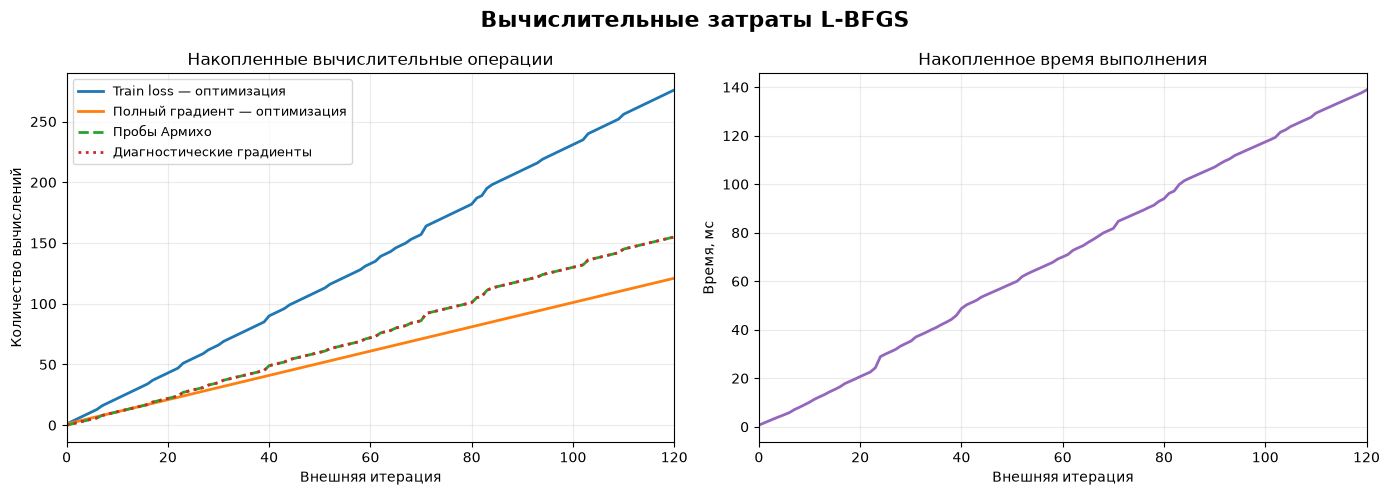

In [14]:
last = history[-1]

# Основные вычислительные затраты
optimizer_loss_calls = last["train_loss_calls"]
optimizer_gradient_calls = last["gradient_calls"]

# Дополнительные диагностические вычисления
diagnostic_loss_calls = last["diagnostic_train_loss_calls"]
diagnostic_gradient_calls = last["diagnostic_gradient_calls"]

validation_calls = last["validation_loss_calls"]

# Суммарные вычислительные затраты
total_train_loss_calls = (
    optimizer_loss_calls + diagnostic_loss_calls
)

total_gradient_calls = (
    optimizer_gradient_calls + diagnostic_gradient_calls
)

total_loss_calls = (
    total_train_loss_calls + validation_calls
)

# Число индивидуальных градиентов
optimizer_individual_grads = (
    optimizer_gradient_calls * len(train_idx)
)

diagnostic_individual_grads = (
    diagnostic_gradient_calls * len(train_idx)
)

# Размер числовых данных памяти L-BFGS
bytes_per_element = theta0.element_size()

bytes_per_pair = (
    (2 * n_parameters + 1) * bytes_per_element
)

max_memory_pairs = int(history_df["memory_pairs"].max())

curvature_memory_bytes = (
    max_memory_pairs * bytes_per_pair
)

# Сводная таблица вычислительных затрат
resources_df = pd.DataFrame({
    "Операция": [
        "Вычисления train loss",
        "Вычисления validation loss",
        "Вычисления полного градиента",
        "Индивидуальные градиенты",
        "Формирование и проверка пар кривизны",
        "Вычисления матрицы Гессе",
        "Решения линейных систем"
    ],

    "Оптимизация": [
        optimizer_loss_calls,
        0,
        optimizer_gradient_calls,
        optimizer_individual_grads,
        last["curvature_calls"],
        last["hessian_calls"],
        last["linear_system_solves"]
    ],

    "Диагностика": [
        diagnostic_loss_calls,
        validation_calls,
        diagnostic_gradient_calls,
        diagnostic_individual_grads,
        0,
        0,
        0
    ]
})

resources_df["Всего"] = (
    resources_df["Оптимизация"]
    + resources_df["Диагностика"]
)

print("Вычислительные затраты:")

display(
    resources_df.style.hide(axis="index")
)

print(
    "\nВычисления функции внутри поиска Армихо:",
    last["line_search_calls"]
)

print(
    "Общее количество вычислений функции потерь:",
    total_loss_calls
)

print(
    "Общее количество вычислений полного градиента:",
    total_gradient_calls
)

# Временные характеристики
time_summary = pd.DataFrame({
    "Показатель": [
        "Полное время эксперимента, мс",
        "Среднее время внешней итерации, мс",
        "Медианное время внешней итерации, мс",
        "Стандартное отклонение времени, мс",
        "Минимальное время итерации, мс",
        "Максимальное время итерации, мс",
        "Суммарное время проб Армихо, мс"
    ],

    "Значение": [
        last["elapsed_time_ms"],
        iteration_df["iteration_time_ms"].mean(),
        iteration_df["iteration_time_ms"].median(),
        iteration_df["iteration_time_ms"].std(),
        iteration_df["iteration_time_ms"].min(),
        iteration_df["iteration_time_ms"].max(),
        trials_df["trial_time_ms"].sum()
    ]
})

print("\nВременные характеристики:")

display(
    time_summary.style
    .hide(axis="index")
    .format({"Значение": "{:.6f}"})
)

# Теоретическая память состояния
memory_summary = pd.DataFrame({
    "Показатель": [
        "Количество параметров сети",
        "Размер одного элемента float64, байт",
        "Размер вектора параметров, байт",
        "Размер одной пары с коэффициентом rho, байт",
        "Максимальное количество сохранённых пар",
        "Размер заполненной памяти L-BFGS, байт"
    ],

    "Значение": [
        n_parameters,
        bytes_per_element,
        n_parameters * bytes_per_element,
        bytes_per_pair,
        max_memory_pairs,
        curvature_memory_bytes
    ]
})

print("\nТеоретическая оценка памяти:")

display(
    memory_summary.style.hide(axis="index")
)

# Графики накопленных вычислительных затрат
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_df["iteration"],
    history_df["train_loss_calls"],
    linewidth=2,
    label="Train loss — оптимизация"
)

axes[0].plot(
    history_df["iteration"],
    history_df["gradient_calls"],
    linewidth=2,
    label="Полный градиент — оптимизация"
)

axes[0].plot(
    history_df["iteration"],
    history_df["line_search_calls"],
    linewidth=2,
    linestyle="--",
    label="Пробы Армихо"
)

axes[0].plot(
    history_df["iteration"],
    history_df["diagnostic_gradient_calls"],
    linewidth=2,
    linestyle=":",
    label="Диагностические градиенты"
)

axes[0].set_title("Накопленные вычислительные операции")
axes[0].set_ylabel("Количество вычислений")
axes[0].legend(fontsize=9)

axes[1].plot(
    history_df["iteration"],
    history_df["elapsed_time_ms"],
    color="#9467bd",
    linewidth=2
)

axes[1].set_title("Накопленное время выполнения")
axes[1].set_ylabel("Время, мс")

for ax in axes:

    ax.set_xlabel("Внешняя итерация")
    ax.set_xlim(0, iterations)
    ax.grid(alpha=0.25)

fig.suptitle(
    "Вычислительные затраты L-BFGS",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [15]:
# Восстановление лучшего состояния нейронной сети
set_parameters(model, theta_best)

assert torch.equal(
    get_parameters(model),
    theta_best
)

model.eval()


# Расчёт метрик регрессии
def regression_metrics(predictions, targets):

    residuals = predictions - targets

    mse = torch.mean(residuals ** 2).item()

    rmse = np.sqrt(mse)

    mae = torch.mean(
        torch.abs(residuals)
    ).item()

    return {
        "Loss": 0.5 * mse,
        "RMSE": rmse,
        "MAE": mae
    }


# Итоговые прогнозы
with torch.no_grad():

    train_predictions = model(X_train)

    val_predictions = model(X_val)

    test_predictions = model(X_test)


# Расчёт метрик для трёх выборок
metric_records = []

for name, predictions, targets in [
    ("Train", train_predictions, y_train),
    ("Validation", val_predictions, y_val),
    ("Test", test_predictions, y_test)
]:

    metrics = regression_metrics(
        predictions,
        targets
    )

    metric_records.append({
        "Выборка": name,
        "Количество наблюдений": len(targets),
        **metrics
    })


metrics_df = pd.DataFrame(metric_records).set_index(
    "Выборка"
)

# Проверка соответствия сохранённой истории
assert np.isclose(
    metrics_df.loc["Train", "Loss"],
    history[best_iteration]["train_loss"],
    atol=1e-12,
    rtol=0
)

assert np.isclose(
    metrics_df.loc["Validation", "Loss"],
    history[best_iteration]["validation_loss"],
    atol=1e-12,
    rtol=0
)

# Проверка связи RMSE с функцией потерь
assert np.allclose(
    metrics_df["RMSE"],
    np.sqrt(2 * metrics_df["Loss"])
)

assert np.isfinite(
    metrics_df[["Loss", "RMSE", "MAE"]]
).all().all()

print("Лучшая итерация:", best_iteration)

print("\nИтоговые метрики регрессии:")

display(
    metrics_df.style.format({
        "Loss": "{:.10f}",
        "RMSE": "{:.10f}",
        "MAE": "{:.10f}"
    })
)

# Подробные результаты на тестовой выборке
test_results_df = pd.DataFrame({
    "x1": X[test_idx, 0],
    "x2": X[test_idx, 1],

    "Фактическое значение": (
        y_test.numpy().ravel()
    ),

    "Прогноз": (
        test_predictions.numpy().ravel()
    )
})

test_results_df["Остаток"] = (
    test_results_df["Фактическое значение"]
    - test_results_df["Прогноз"]
)

test_results_df["Абсолютная ошибка"] = (
    test_results_df["Остаток"].abs()
)

print("\nПервые 10 прогнозов на тестовой выборке:")

display(
    test_results_df.head(10)
    .style.hide(axis="index")
    .format("{:.6f}")
)

# Различие качества на обучающей и тестовой выборках
rmse_gap = (
    metrics_df.loc["Test", "RMSE"]
    - metrics_df.loc["Train", "RMSE"]
)

mae_gap = (
    metrics_df.loc["Test", "MAE"]
    - metrics_df.loc["Train", "MAE"]
)

print(f"\nРазность Test RMSE и Train RMSE: {rmse_gap:+.8f}")
print(f"Разность Test MAE и Train MAE: {mae_gap:+.8f}")

print("\nИтоговая оценка качества завершена.")
print("Тестовая выборка не использовалась при обучении")
print("и выборе лучшей итерации.")

Лучшая итерация: 120

Итоговые метрики регрессии:


,Количество наблюдений,Loss,RMSE,MAE
Выборка,,,,
Train,168,0.0117390810,0.1532258528,0.1077153919
Validation,36,0.0146149228,0.1709673819,0.1105039664
Test,36,0.0067119183,0.1158612815,0.0815823322



Первые 10 прогнозов на тестовой выборке:


x1,x2,Фактическое значение,Прогноз,Остаток,Абсолютная ошибка
-0.325299,0.807175,-0.793728,-0.717417,-0.076311,0.076311
-0.394242,0.900083,-0.674419,-0.689805,0.015386,0.015386
0.231017,-0.438831,0.822616,0.758924,0.063692,0.063692
-0.584396,0.932611,-0.771111,-0.780411,0.009301,0.009301
0.598089,-0.527876,0.918334,0.956362,-0.038029,0.038029
0.938353,0.519270,0.507647,0.449705,0.057942,0.057942
0.970440,-0.731516,0.932037,0.995840,-0.063803,0.063803
0.135784,-0.051340,0.322609,0.292139,0.030471,0.030471
0.521162,-0.314940,0.913658,0.882294,0.031364,0.031364
0.138960,0.483753,-0.526062,-0.406530,-0.119532,0.119532



Разность Test RMSE и Train RMSE: -0.03736457
Разность Test MAE и Train MAE: -0.02613306

Итоговая оценка качества завершена.
Тестовая выборка не использовалась при обучении
и выборе лучшей итерации.


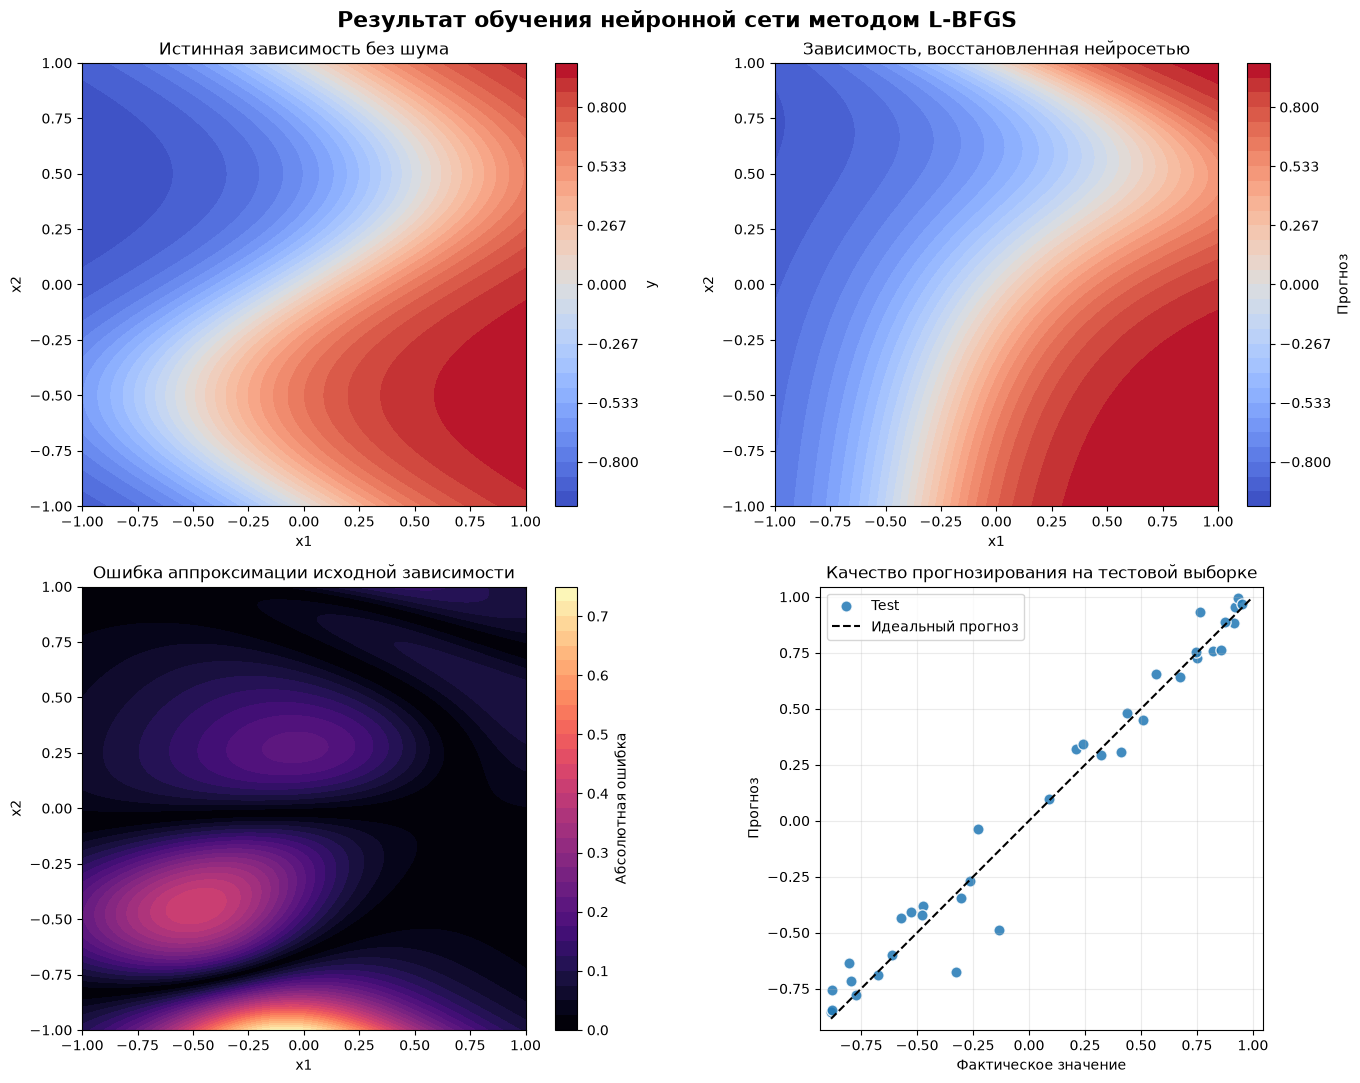

Аппроксимация истинной зависимости на регулярной сетке:
Количество точек сетки: 40000
RMSE: 0.1592960461
MAE: 0.1112045258
Максимальная абсолютная ошибка: 0.7360231932


In [16]:
# Сетка признаков
grid = np.linspace(-1, 1, 200)

X1_grid, X2_grid = np.meshgrid(grid, grid)

grid_points = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
])

grid_tensor = torch.tensor(
    grid_points,
    dtype=torch.float64,
    device=device
)

# Истинная зависимость без шума
Y_true_grid = np.tanh(
    1.5 * X1_grid
    - 0.8 * np.sin(np.pi * X2_grid)
)

# Зависимость, восстановленная нейросетью
set_parameters(model, theta_best)

model.eval()

with torch.no_grad():

    Y_pred_grid = (
        model(grid_tensor)
        .numpy()
        .reshape(X1_grid.shape)
    )

# Абсолютная ошибка аппроксимации
Y_error_grid = np.abs(
    Y_true_grid - Y_pred_grid
)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Единые уровни цветовой шкалы
levels = np.linspace(-1, 1, 31)

# Исходная зависимость
im1 = axes[0, 0].contourf(
    X1_grid,
    X2_grid,
    Y_true_grid,
    levels=levels,
    cmap="coolwarm"
)

fig.colorbar(im1, ax=axes[0, 0], label="y")

axes[0, 0].set_title("Истинная зависимость без шума")

# Восстановленная зависимость
im2 = axes[0, 1].contourf(
    X1_grid,
    X2_grid,
    Y_pred_grid,
    levels=levels,
    cmap="coolwarm"
)

fig.colorbar(im2, ax=axes[0, 1], label="Прогноз")

axes[0, 1].set_title("Зависимость, восстановленная нейросетью")

# Карта абсолютной ошибки
im3 = axes[1, 0].contourf(
    X1_grid,
    X2_grid,
    Y_error_grid,
    levels=30,
    cmap="magma"
)

fig.colorbar(
    im3,
    ax=axes[1, 0],
    label="Абсолютная ошибка"
)

axes[1, 0].set_title("Ошибка аппроксимации исходной зависимости")

# Настройки цветовых карт
for ax in [
    axes[0, 0],
    axes[0, 1],
    axes[1, 0]
]:

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_aspect("equal")

# Фактические значения и прогнозы
actual = y_test.numpy().ravel()

predicted = test_predictions.numpy().ravel()

axes[1, 1].scatter(
    actual,
    predicted,
    color="#1f77b4",
    edgecolor="white",
    s=65,
    alpha=0.85,
    label="Test"
)

# Линия идеального прогнозирования
lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())

axes[1, 1].plot(
    [lower, upper],
    [lower, upper],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Идеальный прогноз"
)

axes[1, 1].set_xlim(lower - 0.05, upper + 0.05)
axes[1, 1].set_ylim(lower - 0.05, upper + 0.05)

axes[1, 1].set_aspect("equal")
axes[1, 1].set_xlabel("Фактическое значение")
axes[1, 1].set_ylabel("Прогноз")
axes[1, 1].set_title("Качество прогнозирования на тестовой выборке")
axes[1, 1].grid(alpha=0.25)
axes[1, 1].legend()

fig.suptitle(
    "Результат обучения нейронной сети методом L-BFGS",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Дополнительная оценка аппроксимации на регулярной сетке
grid_rmse = np.sqrt(
    np.mean((Y_true_grid - Y_pred_grid) ** 2)
)

grid_mae = np.mean(Y_error_grid)

grid_max_error = np.max(Y_error_grid)

print("Аппроксимация истинной зависимости на регулярной сетке:")

print(f"Количество точек сетки: {grid_points.shape[0]}")
print(f"RMSE: {grid_rmse:.10f}")
print(f"MAE: {grid_mae:.10f}")
print(f"Максимальная абсолютная ошибка: {grid_max_error:.10f}")

Диагностика начального состояния сети:


Показатель,Значение
Отрицательные веса выходного слоя,6.00000000
Минимальный начальный прогноз,-0.99961653
Максимальный начальный прогноз,-0.95253362
Средний начальный прогноз,-0.98835606
Средняя производная Tanh,0.02303704



Сравнение качества прогнозирования:


Модель,RMSE,MAE,Максимальная ошибка
Среднее обучающей выборки,0.65178458,0.59893615,0.93290809
Нейронная сеть L-BFGS,0.11586128,0.08158233,0.35102612
Истинная функция без шума,0.02316664,0.01892478,0.05691596


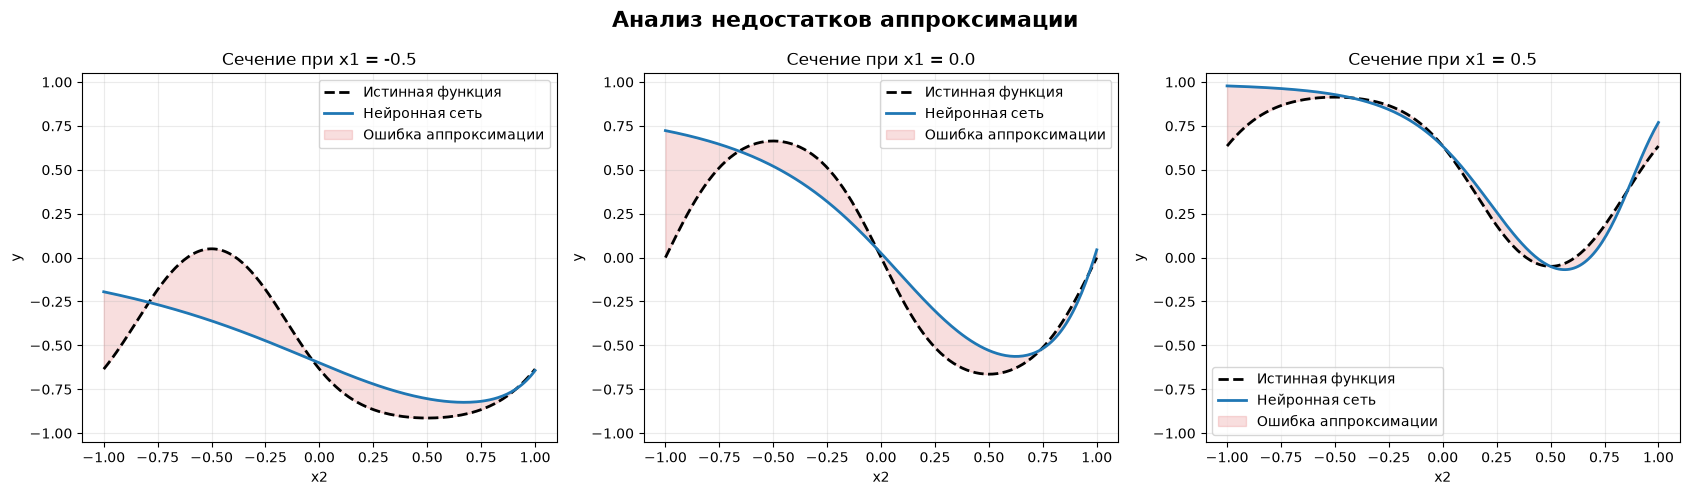

In [17]:
# Дополнительная диагностика качества обучения

# Исследование начального состояния сети
initial_model = initialize_network(network_seed)
set_parameters(initial_model, theta0)

with torch.no_grad():

    initial_hidden = F.softplus(
        initial_model.fc1(X_train)
    )

    initial_logits = initial_model.fc2(initial_hidden)

    initial_predictions = torch.tanh(initial_logits)

    tanh_derivatives = 1 - initial_predictions ** 2

initial_diagnostics = pd.DataFrame({
    "Показатель": [
        "Отрицательные веса выходного слоя",
        "Минимальный начальный прогноз",
        "Максимальный начальный прогноз",
        "Средний начальный прогноз",
        "Средняя производная Tanh"
    ],
    "Значение": [
        (initial_model.fc2.weight < 0).sum().item(),
        initial_predictions.min().item(),
        initial_predictions.max().item(),
        initial_predictions.mean().item(),
        tanh_derivatives.mean().item()
    ]
})

print("Диагностика начального состояния сети:")

display(
    initial_diagnostics.style
    .hide(axis="index")
    .format({"Значение": "{:.8f}"})
)

# Сравнение с контрольными прогнозами
actual = y_test.numpy().ravel()

baseline_predictions = np.full_like(
    actual,
    y_train.mean().item()
)

true_predictions = y_clean[test_idx]

network_predictions = test_predictions.numpy().ravel()

comparison_records = []

for name, predictions in [
    ("Среднее обучающей выборки", baseline_predictions),
    ("Нейронная сеть L-BFGS", network_predictions),
    ("Истинная функция без шума", true_predictions)
]:

    errors = predictions - actual

    comparison_records.append({
        "Модель": name,
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "MAE": np.mean(np.abs(errors)),
        "Максимальная ошибка": np.max(np.abs(errors))
    })

comparison_df = pd.DataFrame(comparison_records)

print("\nСравнение качества прогнозирования:")

display(
    comparison_df.style
    .hide(axis="index")
    .format({
        "RMSE": "{:.8f}",
        "MAE": "{:.8f}",
        "Максимальная ошибка": "{:.8f}"
    })
)

# Визуализация проблемных сечений функции
grid = np.linspace(-1, 1, 200)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

set_parameters(model, theta_best)

for ax, x1_fixed in zip(axes, [-0.5, 0.0, 0.5]):

    points = np.column_stack([
        np.full_like(grid, x1_fixed),
        grid
    ])

    true_section = np.tanh(
        1.5 * x1_fixed
        - 0.8 * np.sin(np.pi * grid)
    )

    with torch.no_grad():

        predicted_section = model(
            torch.tensor(
                points,
                dtype=torch.float64,
                device=device
            )
        ).numpy().ravel()

    ax.plot(
        grid,
        true_section,
        color="black",
        linestyle="--",
        linewidth=2,
        label="Истинная функция"
    )

    ax.plot(
        grid,
        predicted_section,
        color="#1f77b4",
        linewidth=2,
        label="Нейронная сеть"
    )

    ax.fill_between(
        grid,
        true_section,
        predicted_section,
        color="#d62728",
        alpha=0.15,
        label="Ошибка аппроксимации"
    )

    ax.set_title(f"Сечение при x1 = {x1_fixed}")
    ax.set_xlabel("x2")
    ax.set_ylabel("y")
    ax.set_ylim(-1.05, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(
    "Анализ недостатков аппроксимации",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## Анализ результатов эксперимента

**Проверка корректности реализации**

Автоматически вычисленный градиент проверен
методом центральных разностей.

Максимальная абсолютная погрешность составила
$1.09\cdot10^{-11}$, относительная погрешность —
$3.86\cdot10^{-10}$.

На аналитической квадратичной функции реализованный
L-BFGS восстановил известное решение с нулевой
ошибкой в используемой вычислительной точности.

Максимальная погрешность двухцикловой рекурсии
относительно явного обратного BFGS-обновления
составила $3.17\cdot10^{-16}$.

Подтверждены корректность поиска Армихо, пропуск
недопустимых пар кривизны и соблюдение ограничения
размера памяти.

## Сходимость нейронной сети

За 120 внешних итераций получены следующие результаты:

| Показатель | Начальное значение | Итоговое значение |
|---|---:|---:|
| Train loss | 0.71452802 | 0.01173908 |
| Validation loss | 0.82822052 | 0.01461492 |
| Норма полного градиента | 0.06633409 | 0.04602345 |

Обучающие потери уменьшились на 98.3571%,
валидационные — на 98.2354%.

Наиболее интенсивное снижение функции потерь
наблюдалось на начальных итерациях. Примерно
с 20-й до 80-й итерации скорость уменьшения
потерь снизилась, после чего оптимизация
продолжилась более интенсивно.

Минимальная норма полного градиента достигнута
на 47-й итерации:

$$
\min_t\|g_t\|_2=7.7674\cdot10^{-4}.
$$

Однако на последующих итерациях норма градиента
увеличивалась при дальнейшем снижении обучающих
потерь.

Условие Армихо обеспечивает достаточное уменьшение
целевой функции, но не гарантирует монотонного
уменьшения нормы градиента.

Поскольку итоговая норма градиента остаётся
ненулевой, достижение стационарной точки
за 120 итераций не подтверждено.

## Устойчивость и работа механизмов L-BFGS

**Поиск шага Армихо**

| Показатель | Значение |
|---|---:|
| Внешние итерации | 120 |
| Принятые шаги | 120 |
| Отклонённые внешние шаги | 0 |
| Всего проб Армихо | 155 |
| Неуспешные пробные попытки | 35 |
| Шаги, принятые с первой попытки | 101 |
| Итерации с уменьшением шага | 19 |
| Среднее количество проб | 1.291667 |
| Максимальное количество проб | 6 |
| Минимальный принятый шаг | 0.03125 |

Все внешние итерации завершились принятием шага.

На 19 итерациях начальный пробный шаг требовал
уменьшения. Поиск Армихо позволил подобрать
допустимую величину обновления без изменения
заданных гиперпараметров оптимизатора.

Обучающая функция потерь не увеличивалась
ни на одной итерации.

Валидационные потери увеличивались на 52 итерациях,
поскольку валидационная выборка не участвует
в выборе направления и величины шага.

**Формирование пар кривизны**

| Показатель | Значение |
|---|---:|
| Сформированные пары | 120 |
| Допустимые пары | 114 |
| Пропущенные пары | 6 |
| Удалённые старые пары | 109 |
| Итоговое количество пар в памяти | 5 |

На первых шести итерациях условие

$$
s_t^Ty_t>10^{-10}
$$

не выполнялось.

Недопустимые пары были пропущены. До появления
первой допустимой пары алгоритм использовал
направление антиградиента.

После заполнения памяти сохранялись только пять
последних допустимых пар кривизны.

Механизмы проверки кривизны и поиска шага
Армихо были реально задействованы в эксперименте.

Нечисловых значений и отклонённых внешних
обновлений в основном эксперименте не обнаружено.

## Вычислительные затраты

| Операция | Оптимизация | Диагностика | Всего |
|---|---:|---:|---:|
| Вычисления train loss | 276 | 155 | 431 |
| Вычисления validation loss | 0 | 276 | 276 |
| Вычисления полного градиента | 121 | 155 | 276 |
| Индивидуальные градиенты | 20328 | 26040 | 46368 |
| Формирование и проверка пар кривизны | 120 | 0 | 120 |
| Вычисления матрицы Гессе | 0 | 0 | 0 |
| Решения линейных систем | 0 | 0 | 0 |

Для работы самого оптимизатора потребовалось
121 вычисление полного градиента: одно в начальной
точке и 120 после принятых шагов.

Внутри поиска Армихо выполнено 155 вычислений
обучающей функции потерь.

Дополнительные диагностические вычисления
проводились для сохранения характеристик каждой
пробной точки и не использовались при принятии
решений оптимизатором.

Общее количество вычислений функции потерь
в процессе оптимизации и её диагностики — 707.

Временные характеристики представлены в таблице
time_summary. Измеренное время включает
диагностические вычисления и сохранение истории
и может изменяться при повторном запуске.

При количестве параметров $p=25$ и размере
памяти $m=5$ числовые данные заполненной памяти
L-BFGS занимают:

$$
M=m(2p+1)\cdot8
=2040\text{ байт}.
$$

Вычислительная сложность двухцикловой рекурсии
и дополнительная память составляют $O(mp)$.

Явное построение матрицы Гессе и решение
линейных систем в основном эксперименте
не требовались.

Указанный размер памяти характеризует только
хранимые пары кривизны и их коэффициенты,
а не полную память процесса обучения.

## Качество на независимых данных

Итоговое состояние нейронной сети выбрано
по минимальному значению validation loss.

Лучшей оказалась 120-я итерация.

| Выборка | Loss | RMSE | MAE |
|---|---:|---:|---:|
| Train | 0.01173908 | 0.15322585 | 0.10771539 |
| Validation | 0.01461492 | 0.17096738 | 0.11050397 |
| Test | 0.00671192 | 0.11586128 | 0.08158233 |

На независимой тестовой выборке получены:

$$
\operatorname{RMSE}_{test}=0.11586128,
$$

$$
\operatorname{MAE}_{test}=0.08158233.
$$

Тестовые ошибки оказались ниже обучающих
и валидационных. Это может быть связано
со случайным составом небольшой тестовой
выборки из 36 наблюдений.

Данный результат сам по себе не является
доказательством отсутствия переобучения.

Тестовая выборка не использовалась при обучении,
подборе параметров или выборе лучшей итерации.

## Анализ восстановления исходной зависимости

Дополнительно выполнено сравнение прогнозов
нейронной сети с известной функцией генерации
данных без случайного шума на регулярной сетке
из 40000 точек.

| Показатель | Значение |
|---|---:|
| RMSE | 0.15929605 |
| MAE | 0.11120453 |
| Максимальная абсолютная ошибка | 0.73602319 |

Нейронная сеть воспроизвела общий характер
нелинейной зависимости, но не полностью
восстановила её локальные изгибы.

Наиболее заметные ошибки наблюдаются в нижней
части области признаков, в частности вблизи
границы $x_2=-1$.

Ошибки прогнозирования превышают заданный
масштаб случайного шума $\sigma=0.02$.

Это указывает на наличие ошибки аппроксимации,
не сводящейся только к шуму наблюдений.

Возможными причинами являются ограниченная
архитектура сети, конечное количество обучающих
наблюдений, выбранная инициализация и ограниченный
бюджет оптимизации.

Влияние каждой из этих причин отдельно
не исследовалось.
## Дополнительная диагностика недостатков обучения

При исследовании начального состояния сети
установлено, что все шесть весов выходного
слоя имеют отрицательные значения.

Поскольку Softplus принимает положительные
значения, начальные логиты выходного слоя
оказались отрицательными.

| Показатель | Значение |
|---|---:|
| Минимальный начальный прогноз | -0.99961653 |
| Максимальный начальный прогноз | -0.95253362 |
| Средний начальный прогноз | -0.98835606 |
| Средняя производная Tanh | 0.02303704 |

Начальное состояние характеризуется насыщением
выходной активации Tanh.

Малые значения её производной ограничивают
передачу градиента и могут затруднять оптимизацию
на начальных итерациях.

Влияние инициализации на итоговый результат
отдельным экспериментом не проверялось.

**Сравнение с контрольными прогнозами**

| Модель | RMSE | MAE |
|---|---:|---:|
| Среднее обучающей выборки | 0.65178458 | 0.59893615 |
| Нейронная сеть L-BFGS | 0.11586128 | 0.08158233 |
| Истинная функция без шума | 0.02316664 | 0.01892478 |

Нейронная сеть существенно превосходит
простейший прогноз средним значением.

Однако её RMSE примерно в пять раз превышает
ошибку прогнозирования известной функцией
генерации данных.

Анализ сечений при фиксированных значениях
первого признака показал, что сеть не смогла
полностью воспроизвести немонотонный характер
исходной зависимости.

Особенно выраженные отклонения наблюдаются
при отрицательных значениях второго признака.

Полученные результаты свидетельствуют
о недостаточной точности аппроксимации,
несмотря на значительное уменьшение
обучающих потерь.
## Ограничения эксперимента

- Использовалась одна синтетическая выборка.
- Исследована одна архитектура нейронной сети.
- Использована одна фиксированная инициализация.
- Количество итераций ограничено условиями задания.
- Сравнение с другими оптимизаторами не проводилось.
- Достижение глобального минимума не доказано.
- Измеренное время зависит от вычислительной среды.

## Вывод

В работе самостоятельно реализован метод L-BFGS
для обучения нейронной сети с архитектурой
2 → 6 → 1.

Корректность реализации подтверждена проверкой
градиентов, аналитическим контрольным экспериментом
и сравнением двухцикловой рекурсии с явным
обратным BFGS-обновлением.

За 120 внешних итераций обучающие потери
уменьшились на 98.36%, валидационные — на 98.24%.
Все внешние шаги были успешно приняты.

При этом достижение стационарной точки
не подтверждено. Норма полного градиента
изменялась немонотонно.

На тестовой выборке получены RMSE = 0.11586128
и MAE = 0.08158233.

Ошибка прогнозирования примерно в пять раз
превышает ошибку известной функции генерации
данных. Максимальная ошибка аппроксимации
на регулярной сетке составила 0.73602319.

Дополнительная диагностика выявила насыщение
выходной активации в начальном состоянии
и недостаточное восстановление отдельных
нелинейных участков исходной функции.

При заданной архитектуре, инициализации
и вычислительном бюджете результат обучения
следует считать частично успешным.

Несмотря на корректность реализации L-BFGS
и существенное уменьшение функции потерь,
высокой точности восстановления исходной
зависимости достичь не удалось.

Установить, какой именно фактор оказал
наибольшее влияние на итоговое качество,
в рамках проведённого эксперимента невозможно.